<a href="https://colab.research.google.com/github/dewaputufajar308/Tugas3-Visualisasi-Data-Teks/blob/main/notebooks/Tugas3_Teks_203012510036_Dewa_Putu_Fajar_W.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [73]:

# ============================================================
# TUGAS 3 — VISUALISASI DATA TEKS
# CELL 1: INISIALISASI PROYEK DAN PEMUATAN DATASET
# ============================================================

import os
import subprocess
import pandas as pd
import numpy as np
import re
import html
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Repository GitHub
REPO_URL = "https://github.com/dewaputufajar308/Tugas3-Visualisasi-Data-Teks.git"
REPO_DIR = "/content/Tugas3-Visualisasi-Data-Teks"

# Clone repository jika belum tersedia
if not os.path.isdir(REPO_DIR):
    subprocess.run(
        ["git", "clone", REPO_URL, REPO_DIR],
        check=True
    )

os.chdir(REPO_DIR)

# 2. Direktori proyek
DATA_DIR = os.path.join(REPO_DIR, "data")
OUTPUT_DIR = os.path.join(REPO_DIR, "outputs")

os.makedirs(os.path.join(OUTPUT_DIR, "figures"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "tables"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "reports"), exist_ok=True)

# 3. Cari dataset aduan secara otomatis
kandidat_csv = []

for root, dirs, files in os.walk(DATA_DIR):
    dirs[:] = [d for d in dirs if d != ".git"]

    for file in files:
        if file.lower().endswith("_aduan.csv"):
            kandidat_csv.append(os.path.join(root, file))

if len(kandidat_csv) != 1:
    raise FileNotFoundError(
        "Harus ditemukan tepat satu file *_aduan.csv. "
        f"Kandidat yang ditemukan: {kandidat_csv}"
    )

DATA_PATH = kandidat_csv[0]

# 4. Muat dataset
aduan_df = pd.read_csv(DATA_PATH)

# 5. Pemeriksaan awal
kolom_wajib = [
    "id_aduan",
    "tanggal",
    "kategori_dilaporkan",
    "isi_aduan"
]

kolom_hilang = [
    kolom for kolom in kolom_wajib
    if kolom not in aduan_df.columns
]

if kolom_hilang:
    raise ValueError(f"Kolom wajib tidak ditemukan: {kolom_hilang}")

print("INISIALISASI BERHASIL")
print("Repository :", REPO_DIR)
print("Dataset    :", DATA_PATH)
print("Jumlah data:", f"{len(aduan_df):,}")
print("Jumlah kolom:", len(aduan_df.columns))

print("\nStruktur dataset:")
display(aduan_df.head())

print("\nInformasi tipe data:")
display(aduan_df.dtypes.rename("tipe_data").to_frame())


INISIALISASI BERHASIL
Repository : /content/Tugas3-Visualisasi-Data-Teks
Dataset    : /content/Tugas3-Visualisasi-Data-Teks/data/raw/extracted/203012510036_aduan.csv
Jumlah data: 5,049
Jumlah kolom: 9

Struktur dataset:


,id_aduan,tanggal,kanal,kelurahan,kategori_dilaporkan,isi_aduan,lon,lat,status
0,ADU-002330,2026-03-16,Datang Langsung,Ciburial,Sampah,"Punten ngaganggu waktosna, Sampah menumpuk di TPS Perumahan Griya Asri tidak diangkut petugas. K...",107.566695,-6.925499,Selesai
1,ADU-004318,2025-09-12,Web,Sekejati,Ketertiban Umum,"Assalamualaikum Bapak/Ibu, Parkir liar di Jalan Cendana Raya menutup separuh badan jalan. Kami k...",107.614777,-6.915453,Selesai
2,ADU-001600,2025-10-17,Web,Sekejati,Lain-lain,"Assalamualaikum Bapak/Ibu, Suara bising dari bengkel di Komplek Pondok Hijau sampai tengah malam...",107.618543,-6.912097,Diteruskan
3,ADU-003353,2026-08-11,Aplikasi Mobile,Cisaranten,Ketertiban Umum,"Penerangan jalan umum di Gang Kenanga tidak menyala sama sekali. Kumaha atuh Pa, hatur nuhun.",107.611433,-6.928716,Diteruskan
4,ADU-001236,28/05/2026,Surat,Kebon Gedang,Ketertiban Umum,"Mohon perhatiannya, Kendaraan parkir di badan jalan depan Gang Melati menyebabkan macet panjang....",107.591213,-6.910023,Selesai



Informasi tipe data:


,tipe_data
id_aduan,object
tanggal,object
kanal,object
kelurahan,object
kategori_dilaporkan,object
isi_aduan,object
lon,float64
lat,float64
status,object


# Bagian A - Audit kualitas korpus

## AUDIT AWAL TEKS, DUPLIKASI, DAN TEKS TIDAK VALID

In [74]:

# ============================================================
# BAGIAN A - CELL 2
# AUDIT AWAL TEKS, DUPLIKASI, DAN TEKS TIDAK VALID
# ============================================================

import re
import html
import pandas as pd

# Salinan teks untuk pemeriksaan, data asli tidak diubah
teks = aduan_df["isi_aduan"].fillna("").astype(str)

# Fungsi normalisasi khusus untuk mendeteksi duplikasi
def normalisasi_duplikat(text):
    text = html.unescape(str(text)).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

teks_norm = teks.apply(normalisasi_duplikat)

# 1. Pemeriksaan teks kosong dan sangat pendek
kosong = teks.str.strip().eq("")
sangat_pendek = (~kosong) & (teks.str.strip().str.len() <= 2)

# 2. Kandidat teks uji coba / bukan aduan
pola_uji = r"^(tes|test|testing|coba|halo|hai|asdf|qwerty)[\s!.?]*$"
kandidat_uji = (
    (~kosong) &
    teks_norm.str.fullmatch(pola_uji, na=False)
)

# 3. Duplikasi persis
duplikat_persis = (
    (~kosong) &
    teks.duplicated(keep="first")
)

# 4. Duplikasi setelah normalisasi
duplikat_normalisasi = (
    (teks_norm != "") &
    teks_norm.duplicated(keep="first")
)

# Jumlah baris berlebih akibat duplikasi
jumlah_duplikat_persis = int(duplikat_persis.sum())
jumlah_duplikat_normalisasi = int(duplikat_normalisasi.sum())

# 5. Statistik panjang teks
jumlah_karakter = teks.str.len()
jumlah_kata = teks.str.split().str.len()

# 6. Ringkasan audit
audit_awal = pd.DataFrame({
    "Aspek pemeriksaan": [
        "Total aduan",
        "Teks kosong",
        "Teks sangat pendek (maks. 2 karakter)",
        "Kandidat teks uji coba/bukan aduan",
        "Duplikasi persis (baris berlebih)",
        "Duplikasi setelah normalisasi (baris berlebih)"
    ],
    "Jumlah": [
        len(aduan_df),
        int(kosong.sum()),
        int(sangat_pendek.sum()),
        int(kandidat_uji.sum()),
        jumlah_duplikat_persis,
        jumlah_duplikat_normalisasi
    ]
})

audit_awal["Persentase"] = (
    audit_awal["Jumlah"] / len(aduan_df) * 100
).round(2)

print("HASIL AUDIT AWAL KORPUS")
display(audit_awal)

print("\nSTATISTIK PANJANG TEKS")
display(pd.DataFrame({
    "Ukuran": ["Karakter", "Kata"],
    "Rata-rata": [
        round(jumlah_karakter.mean(), 2),
        round(jumlah_kata.mean(), 2)
    ],
    "Median": [
        round(jumlah_karakter.median(), 2),
        round(jumlah_kata.median(), 2)
    ],
    "Minimum": [
        int(jumlah_karakter.min()),
        int(jumlah_kata.min())
    ],
    "Maksimum": [
        int(jumlah_karakter.max()),
        int(jumlah_kata.max())
    ]
}))

print("\nCatatan: seluruh temuan masih berupa hasil audit.")
print("Belum ada baris data yang dihapus atau diubah.")


HASIL AUDIT AWAL KORPUS


,Aspek pemeriksaan,Jumlah,Persentase
0,Total aduan,5049,100.00
1,Teks kosong,7,0.14
2,Teks sangat pendek (maks. 2 karakter),14,0.28
3,Kandidat teks uji coba/bukan aduan,35,0.69
4,Duplikasi persis (baris berlebih),160,3.17
5,Duplikasi setelah normalisasi (baris berlebih),166,3.29



STATISTIK PANJANG TEKS


,Ukuran,Rata-rata,Median,Minimum,Maksimum
0,Karakter,171.2,170.0,0,704
1,Kata,24.4,24.0,0,108



Catatan: seluruh temuan masih berupa hasil audit.
Belum ada baris data yang dihapus atau diubah.


## AUDIT NORMALISASI, EJAAN, DAN VARIASI BAHASA

In [75]:

# ============================================================
# BAGIAN A - CELL 3
# AUDIT NORMALISASI, EJAAN, DAN VARIASI BAHASA
# ============================================================

import re
import html
import pandas as pd
from collections import Counter

teks_asli = aduan_df["isi_aduan"].fillna("").astype(str)

# 1. Fungsi normalisasi teks
def normalisasi_teks(teks):
    teks = html.unescape(str(teks))
    teks = re.sub(r"<[^>]+>", " ", teks)
    teks = teks.lower()
    teks = re.sub(r"\s+", " ", teks).strip()
    return teks

aduan_df["teks_normalisasi"] = teks_asli.apply(normalisasi_teks)

# 2. Audit perubahan format
audit_format = pd.DataFrame({
    "Aspek": [
        "Mengandung huruf kapital",
        "Mengandung spasi berlebihan",
        "Mengandung HTML tag",
        "Mengandung HTML entity",
        "Teks berubah setelah normalisasi"
    ],
    "Jumlah": [
        teks_asli.apply(lambda x: x != x.lower()).sum(),
        teks_asli.str.contains(r"\s{2,}", regex=True).sum(),
        teks_asli.str.contains(r"<[^>]+>", regex=True).sum(),
        teks_asli.str.contains(
            r"&(?:amp|lt|gt|quot|nbsp);",
            case=False, regex=True
        ).sum(),
        (teks_asli != aduan_df["teks_normalisasi"]).sum()
    ]
})

print("AUDIT FORMAT TEKS")
display(audit_format)

# 3. Kandidat ejaan tidak baku dan singkatan informal
kamus_informal = {
    "gak", "nggak", "enggak", "ga", "gk",
    "yg", "dgn", "utk", "krn", "karna",
    "bgt", "aja", "jd", "dr", "sdh",
    "blm", "tdk", "tp", "sm", "sy",
    "km", "klo", "kl", "trs", "udah"
}

frekuensi_kata = Counter(
    kata
    for teks in aduan_df["teks_normalisasi"]
    for kata in re.findall(r"\b[a-z]+\b", teks)
)

temuan_informal = {
    kata: jumlah
    for kata, jumlah in frekuensi_kata.items()
    if kata in kamus_informal
}

tabel_informal = pd.DataFrame(
    sorted(
        temuan_informal.items(),
        key=lambda x: x[1],
        reverse=True
    ),
    columns=["Kata", "Frekuensi"]
)

print("\nKANDIDAT EJAAN TIDAK BAKU / SINGKATAN")
display(tabel_informal)

# 4. Indikasi istilah bahasa Inggris
indikator_inggris = {
    "parking", "street", "light", "road", "water",
    "drainage", "garbage", "waste", "traffic",
    "public", "service", "broken", "flood",
    "lamp", "building", "management"
}

temuan_inggris = {
    kata: jumlah
    for kata, jumlah in frekuensi_kata.items()
    if kata in indikator_inggris
}

tabel_inggris = pd.DataFrame(
    sorted(
        temuan_inggris.items(),
        key=lambda x: x[1],
        reverse=True
    ),
    columns=["Istilah", "Frekuensi"]
)

print("\nINDIKASI ISTILAH BAHASA INGGRIS")
display(tabel_inggris)

# 5. Contoh teks yang berubah setelah normalisasi
contoh_normalisasi = aduan_df.loc[
    teks_asli != aduan_df["teks_normalisasi"],
    ["id_aduan", "isi_aduan", "teks_normalisasi"]
].head(5)

print("\nCONTOH SEBELUM DAN SESUDAH NORMALISASI")
display(contoh_normalisasi)

print("\nAudit normalisasi, ejaan, dan variasi bahasa selesai.")
print("Teks asli tetap dipertahankan.")


AUDIT FORMAT TEKS


,Aspek,Jumlah
0,Mengandung huruf kapital,4982
1,Mengandung spasi berlebihan,3
2,Mengandung HTML tag,117
3,Mengandung HTML entity,22
4,Teks berubah setelah normalisasi,4982



KANDIDAT EJAAN TIDAK BAKU / SINGKATAN


,Kata,Frekuensi
0,aja,3



INDIKASI ISTILAH BAHASA INGGRIS


,Istilah,Frekuensi



CONTOH SEBELUM DAN SESUDAH NORMALISASI


,id_aduan,isi_aduan,teks_normalisasi
0,ADU-002330,"Punten ngaganggu waktosna, Sampah menumpuk di TPS Perumahan Griya Asri tidak diangkut petugas. K...","punten ngaganggu waktosna, sampah menumpuk di tps perumahan griya asri tidak diangkut petugas. k..."
1,ADU-004318,"Assalamualaikum Bapak/Ibu, Parkir liar di Jalan Cendana Raya menutup separuh badan jalan. Kami k...","assalamualaikum bapak/ibu, parkir liar di jalan cendana raya menutup separuh badan jalan. kami k..."
2,ADU-001600,"Assalamualaikum Bapak/Ibu, Suara bising dari bengkel di Komplek Pondok Hijau sampai tengah malam...","assalamualaikum bapak/ibu, suara bising dari bengkel di komplek pondok hijau sampai tengah malam..."
3,ADU-003353,"Penerangan jalan umum di Gang Kenanga tidak menyala sama sekali. Kumaha atuh Pa, hatur nuhun.","penerangan jalan umum di gang kenanga tidak menyala sama sekali. kumaha atuh pa, hatur nuhun."
4,ADU-001236,"Mohon perhatiannya, Kendaraan parkir di badan jalan depan Gang Melati menyebabkan macet panjang....","mohon perhatiannya, kendaraan parkir di badan jalan depan gang melati menyebabkan macet panjang...."



Audit normalisasi, ejaan, dan variasi bahasa selesai.
Teks asli tetap dipertahankan.


## AUDIT INFORMASI PRIBADI DAN PENYAMARAN

In [76]:

# ============================================================
# BAGIAN A - CELL 4
# AUDIT INFORMASI PRIBADI DAN PENYAMARAN
# ============================================================

import re
import pandas as pd

# Gunakan teks asli untuk mendeteksi informasi pribadi
teks_asli = aduan_df["isi_aduan"].fillna("").astype(str)

# Pola deteksi
pola = {
    "Nomor telepon": r"(?<!\d)(?:\+62|62|0)[\s.-]?8(?:[\s.-]?\d){7,12}(?!\d)",
    "NIK (16 digit)": r"(?<!\d)\d{16}(?!\d)",
    "Alamat email": r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
    "URL": r"(?:https?://|www\.)[^\s<>]+"
}

# Deteksi per baris, tanpa menampilkan teks sensitif
hasil_deteksi = pd.DataFrame({
    nama: teks_asli.str.contains(regex, regex=True, na=False)
    for nama, regex in pola.items()
})

# Ringkasan per jenis informasi
ringkasan_privasi = pd.DataFrame({
    "Jenis informasi": list(pola.keys()),
    "Jumlah aduan": hasil_deteksi.sum().values
})

ringkasan_privasi["Persentase dari korpus"] = (
    ringkasan_privasi["Jumlah aduan"] / len(aduan_df) * 100
).round(2)

# Hitung aduan yang mengandung minimal satu jenis informasi
ada_privasi = hasil_deteksi.any(axis=1)

print("HASIL AUDIT INFORMASI PRIBADI")
display(ringkasan_privasi)

print("Total aduan dengan minimal satu indikasi informasi pribadi:",
      int(ada_privasi.sum()))

print("Persentase dari seluruh korpus:",
      round(ada_privasi.mean() * 100, 2), "%")

# Buat salinan teks yang telah disamarkan
def samarkan_privasi(teks):
    teks = str(teks)

    # Samarkan email
    teks = re.sub(pola["Alamat email"], "[EMAIL DISAMARKAN]", teks)

    # Samarkan URL
    teks = re.sub(pola["URL"], "[URL DISAMARKAN]", teks)

    # Samarkan NIK
    teks = re.sub(pola["NIK (16 digit)"], "[NIK DISAMARKAN]", teks)

    # Samarkan nomor telepon
    teks = re.sub(
        pola["Nomor telepon"],
        "[TELEPON DISAMARKAN]",
        teks
    )

    return teks

aduan_df["teks_aman"] = aduan_df["teks_normalisasi"].apply(
    samarkan_privasi
)

print("\nKolom teks_aman berhasil dibuat.")
print("Teks asli dan teks normalisasi tetap dipertahankan.")


HASIL AUDIT INFORMASI PRIBADI


,Jenis informasi,Jumlah aduan,Persentase dari korpus
0,Nomor telepon,105,2.08
1,NIK (16 digit),43,0.85
2,Alamat email,0,0.00
3,URL,0,0.00


Total aduan dengan minimal satu indikasi informasi pribadi: 148
Persentase dari seluruh korpus: 2.93 %

Kolom teks_aman berhasil dibuat.
Teks asli dan teks normalisasi tetap dipertahankan.


## AUDIT TANGGAL DAN KELENGKAPAN DATA

In [77]:

# ============================================================
# BAGIAN A - CELL 5
# AUDIT TANGGAL DAN KELENGKAPAN DATA
# ============================================================

import pandas as pd

# 1. Audit format tanggal asli
tanggal_asli = aduan_df["tanggal"].astype("string").str.strip()

format_iso = tanggal_asli.str.match(
    r"^\d{4}-\d{2}-\d{2}$", na=False
)

format_dmy = tanggal_asli.str.match(
    r"^\d{2}/\d{2}/\d{4}$", na=False
)

format_lain = ~(format_iso | format_dmy | tanggal_asli.isna())

# 2. Konversi tanggal berdasarkan dua format yang ditemukan
tanggal_iso = pd.to_datetime(
    tanggal_asli.where(format_iso),
    format="%Y-%m-%d",
    errors="coerce"
)

tanggal_dmy = pd.to_datetime(
    tanggal_asli.where(format_dmy),
    format="%d/%m/%Y",
    errors="coerce"
)

aduan_df["tanggal_parsed"] = tanggal_iso.fillna(tanggal_dmy)

# 3. Ringkasan tanggal
tanggal_valid = aduan_df["tanggal_parsed"].notna()

audit_tanggal = pd.DataFrame({
    "Aspek": [
        "Format YYYY-MM-DD",
        "Format DD/MM/YYYY",
        "Format lainnya",
        "Tanggal berhasil dikonversi",
        "Tanggal gagal dikonversi"
    ],
    "Jumlah": [
        int(format_iso.sum()),
        int(format_dmy.sum()),
        int(format_lain.sum()),
        int(tanggal_valid.sum()),
        int((~tanggal_valid).sum())
    ]
})

print("HASIL AUDIT FORMAT TANGGAL")
display(audit_tanggal)

if tanggal_valid.any():
    print("Rentang tanggal valid:")
    print(aduan_df["tanggal_parsed"].min(), "sampai",
          aduan_df["tanggal_parsed"].max())

# 4. Audit kelengkapan kolom penting
kolom_penting = [
    "id_aduan",
    "tanggal",
    "kategori_dilaporkan",
    "isi_aduan"
]

audit_kelengkapan = pd.DataFrame({
    "Kolom": kolom_penting,
    "Nilai kosong": [
        int(aduan_df[col].isna().sum())
        for col in kolom_penting
    ],
    "Persentase kosong": [
        round(aduan_df[col].isna().mean() * 100, 2)
        for col in kolom_penting
    ]
})

print("\nHASIL AUDIT KELENGKAPAN DATA")
display(audit_kelengkapan)

# 5. Audit ID duplikat
jumlah_id_duplikat = int(
    aduan_df["id_aduan"].duplicated().sum()
)

print("\nJUMLAH ID ADUAN DUPLIKAT:", jumlah_id_duplikat)

print("\nAudit tanggal dan kelengkapan data selesai.")
print("Belum ada baris yang dihapus.")


HASIL AUDIT FORMAT TANGGAL


,Aspek,Jumlah
0,Format YYYY-MM-DD,4645
1,Format DD/MM/YYYY,404
2,Format lainnya,0
3,Tanggal berhasil dikonversi,5049
4,Tanggal gagal dikonversi,0


Rentang tanggal valid:
2025-09-01 00:00:00 sampai 2026-08-31 00:00:00

HASIL AUDIT KELENGKAPAN DATA


,Kolom,Nilai kosong,Persentase kosong
0,id_aduan,0,0.00
1,tanggal,0,0.00
2,kategori_dilaporkan,0,0.00
3,isi_aduan,7,0.14



JUMLAH ID ADUAN DUPLIKAT: 0

Audit tanggal dan kelengkapan data selesai.
Belum ada baris yang dihapus.


## AUDIT KESESUAIAN KATEGORI DENGAN ISI ADUAN

In [78]:

# ============================================================
# BAGIAN A - CELL 6
# AUDIT KESESUAIAN KATEGORI DENGAN ISI ADUAN
# ============================================================

# Gunakan hanya aduan dengan teks yang tersedia
data_kategori = aduan_df[
    aduan_df["isi_aduan"].notna() &
    (aduan_df["isi_aduan"].astype(str).str.strip() != "")
].copy()

# Distribusi kategori yang dilaporkan
distribusi_kategori = (
    data_kategori["kategori_dilaporkan"]
    .value_counts()
    .rename_axis("Kategori")
    .reset_index(name="Jumlah aduan")
)

distribusi_kategori["Persentase"] = (
    distribusi_kategori["Jumlah aduan"] /
    len(data_kategori) * 100
).round(2)

print("DISTRIBUSI KATEGORI YANG DILAPORKAN")
display(distribusi_kategori)

# Pengambilan sampel stratifikasi
JUMLAH_SAMPEL_PER_KATEGORI = 30

kategori_review = (
    data_kategori
    .groupby("kategori_dilaporkan", group_keys=False)
    .apply(
        lambda x: x.sample(
            n=min(JUMLAH_SAMPEL_PER_KATEGORI, len(x)),
            random_state=42
        ),
        include_groups=True
    )
    .reset_index(drop=True)
)

# Siapkan template pemeriksaan manual
category_review = kategori_review[
    ["id_aduan", "kategori_dilaporkan", "teks_aman"]
].copy()

category_review = category_review.rename(
    columns={"teks_aman": "isi_aduan"}
)

category_review["pokok_masalah_sebenarnya"] = ""
category_review["kesesuaian"] = ""
category_review["catatan_pemeriksaan"] = ""

print("\nJUMLAH SAMPEL PEMERIKSAAN:",
      len(category_review))

print("\nDISTRIBUSI SAMPEL PER KATEGORI:")
display(
    category_review["kategori_dilaporkan"]
    .value_counts()
    .rename_axis("Kategori")
    .reset_index(name="Jumlah sampel")
)

print("\nTEMPLATE PEMERIKSAAN MANUAL:")
display(category_review.head(10))

print(
    "\nIsi pokok_masalah_sebenarnya, kesesuaian "
    "(Sesuai/Berbeda/Tidak dapat diklasifikasikan), "
    "dan catatan_pemeriksaan berdasarkan isi aduan."
)


DISTRIBUSI KATEGORI YANG DILAPORKAN


,Kategori,Jumlah aduan,Persentase
0,Jalan Rusak,955,18.94
1,Penerangan Jalan,834,16.54
2,Sampah,787,15.61
3,Drainase dan Banjir,589,11.68
4,Fasilitas Umum,530,10.51
5,Ketertiban Umum,495,9.82
6,Air Bersih,481,9.54
7,Lain-lain,371,7.36



JUMLAH SAMPEL PEMERIKSAAN: 240

DISTRIBUSI SAMPEL PER KATEGORI:


/tmp/ipykernel_648/2497081780.py:34: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Kategori,Jumlah sampel
0,Air Bersih,30
1,Drainase dan Banjir,30
2,Fasilitas Umum,30
3,Jalan Rusak,30
4,Ketertiban Umum,30
5,Lain-lain,30
6,Penerangan Jalan,30
7,Sampah,30



TEMPLATE PEMERIKSAAN MANUAL:


,id_aduan,kategori_dilaporkan,isi_aduan,pokok_masalah_sebenarnya,kesesuaian,catatan_pemeriksaan
0,ADU-003604,Air Bersih,"assalamualaikum bapak/ibu, air pdam keruh berwarna coklat sejak 4 hari terakhir. atas perhatian ...",,,
1,ADU-004402,Air Bersih,"yth. bapak/ibu wali kota, air keruh kekuningan sudah 7 hari di jalan sukamaju dalam. sudah ada d...",,,
2,ADU-004011,Air Bersih,"punten ngaganggu waktosna, jalan berlubang di perumahan bumi lestari sudah sangat dalam dan berb...",,,
3,ADU-001853,Air Bersih,"assalamualaikum bapak/ibu, aspal jalan mengelupas sepanjang perumahan bumi lestari. kondisi ini ...",,,
4,ADU-001926,Air Bersih,"selamat pagi bapak/ibu, pedagang kaki lima memakai seluruh trotoar di perumahan bumi lestari. wa...",,,
5,ADU-000267,Air Bersih,"yth. bapak wali kota, mohon perhatian serius terhadap kondisi jalan berlubang di seluruh wilayah...",,,
6,ADU-000547,Air Bersih,air tidak mengalir sejak pagi di daerah posyandu rw 07. mohon segera ditindaklanjuti. terima kasih.,,,
7,ADU-005013,Air Bersih,"assalamualaikum bapak/ibu, jalan rusak dan berbatu di jalan kopo hilir sejak 5 bulan tidak diper...",,,
8,ADU-002438,Air Bersih,"kepada bapak/ibu petugas yang bertugas, air keruh kekuningan sudah 5 hari di perumahan griya asr...",,,
9,ADU-004360,Air Bersih,"mohon bantuan bapak/ibu, aliran air kecil sekali pada jam sibuk di gang mawar dalam. kami mohon ...",,,



Isi pokok_masalah_sebenarnya, kesesuaian (Sesuai/Berbeda/Tidak dapat diklasifikasikan), dan catatan_pemeriksaan berdasarkan isi aduan.


## PENYIMPANAN TEMPLATE AUDIT KATEGORI

In [79]:

# ============================================================
# BAGIAN A - PENYIMPANAN TEMPLATE AUDIT KATEGORI
# ============================================================

import os
import pandas as pd

# Pastikan folder penyimpanan tersedia
TABLE_DIR = os.path.join(OUTPUT_DIR, "tables")
os.makedirs(TABLE_DIR, exist_ok=True)

# Siapkan seluruh 240 sampel
category_review = category_review.reset_index(drop=True).copy()

# Pastikan kolom pemeriksaan tersedia
kolom_pemeriksaan = [
    "pokok_masalah_sebenarnya",
    "kesesuaian",
    "catatan_pemeriksaan"
]

for kolom in kolom_pemeriksaan:
    if kolom not in category_review.columns:
        category_review[kolom] = ""

# Simpan template CSV
REVIEW_PATH = os.path.join(
    TABLE_DIR,
    "audit_kesesuaian_kategori_240.csv"
)

category_review.to_csv(
    REVIEW_PATH,
    index=False,
    encoding="utf-8-sig"
)

# Tampilkan seluruh sampel sekaligus
pd.set_option("display.max_rows", 250)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)

print("TEMPLATE AUDIT BERHASIL DISIMPAN")
print("Lokasi:", REVIEW_PATH)
print("Jumlah sampel:", len(category_review))
print("\nSeluruh 240 sampel:")
display(category_review)

print("\nKolom yang perlu diisi:")
print("- pokok_masalah_sebenarnya")
print("- kesesuaian: Sesuai / Berbeda / Tidak dapat diklasifikasikan")
print("- catatan_pemeriksaan")


TEMPLATE AUDIT BERHASIL DISIMPAN
Lokasi: /content/Tugas3-Visualisasi-Data-Teks/outputs/tables/audit_kesesuaian_kategori_240.csv
Jumlah sampel: 240

Seluruh 240 sampel:


,id_aduan,kategori_dilaporkan,isi_aduan,pokok_masalah_sebenarnya,kesesuaian,catatan_pemeriksaan
0,ADU-003604,Air Bersih,"assalamualaikum bapak/ibu, air pdam keruh berwarna coklat sejak 4 hari terakhir. atas perhatian ...",,,
1,ADU-004402,Air Bersih,"yth. bapak/ibu wali kota, air keruh kekuningan sudah 7 hari di jalan sukamaju dalam. sudah ada d...",,,
2,ADU-004011,Air Bersih,"punten ngaganggu waktosna, jalan berlubang di perumahan bumi lestari sudah sangat dalam dan berb...",,,
3,ADU-001853,Air Bersih,"assalamualaikum bapak/ibu, aspal jalan mengelupas sepanjang perumahan bumi lestari. kondisi ini ...",,,
4,ADU-001926,Air Bersih,"selamat pagi bapak/ibu, pedagang kaki lima memakai seluruh trotoar di perumahan bumi lestari. wa...",,,
5,ADU-000267,Air Bersih,"yth. bapak wali kota, mohon perhatian serius terhadap kondisi jalan berlubang di seluruh wilayah...",,,
6,ADU-000547,Air Bersih,air tidak mengalir sejak pagi di daerah posyandu rw 07. mohon segera ditindaklanjuti. terima kasih.,,,
7,ADU-005013,Air Bersih,"assalamualaikum bapak/ibu, jalan rusak dan berbatu di jalan kopo hilir sejak 5 bulan tidak diper...",,,
8,ADU-002438,Air Bersih,"kepada bapak/ibu petugas yang bertugas, air keruh kekuningan sudah 5 hari di perumahan griya asr...",,,
9,ADU-004360,Air Bersih,"mohon bantuan bapak/ibu, aliran air kecil sekali pada jam sibuk di gang mawar dalam. kami mohon ...",,,



Kolom yang perlu diisi:
- pokok_masalah_sebenarnya
- kesesuaian: Sesuai / Berbeda / Tidak dapat diklasifikasikan
- catatan_pemeriksaan


## PEMERIKSAAN KESESUAIAN KATEGORI 240 SAMPEL

In [80]:

# ============================================================
# BAGIAN A - CELL 7
# PEMERIKSAAN KESESUAIAN KATEGORI 240 SAMPEL
# ============================================================

import os
import re
import pandas as pd

# 1. Pastikan data sampel tersedia
if "category_review" not in globals():
    category_review = pd.read_csv(REVIEW_PATH)

data = category_review.copy()

assert len(data) == 240, (
    f"Jumlah sampel seharusnya 240, ditemukan {len(data)}"
)

# 2. Aturan identifikasi pokok masalah
aturan_kategori = {
    "Air Bersih": [
        r"\bair pdam\b",
        r"\bair keruh\b",
        r"\bair bersih\b",
        r"\baliran air kecil\b",
        r"\bair mati total\b",
        r"\bair tidak mengalir\b"
    ],
    "Drainase dan Banjir": [
        r"\bdrainase\b",
        r"\bsaluran air\b",
        r"\bgorong.?gorong\b",
        r"\bbanjir\b",
        r"\bgenangan\b",
        r"\bair menggenang\b"
    ],
    "Penerangan Jalan": [
        r"\blampu jalan\b",
        r"\blampu pju\b",
        r"\bpenerangan jalan\b",
        r"\bjalan gelap\b",
        r"\btiang lampu\b"
    ],
    "Sampah": [
        r"\bsampah\b",
        r"\bbak sampah\b",
        r"\btumpukan sampah\b",
        r"\bpetugas sampah\b"
    ],
    "Jalan Rusak": [
        r"\bjalan berlubang\b",
        r"\bjalan rusak\b",
        r"\baspal .*mengelupas\b",
        r"\baspal jalan\b",
        r"\bjalan berbatu\b",
        r"\blubang jalan\b"
    ],
    "Ketertiban Umum": [
        r"\bpedagang kaki lima\b",
        r"\bparkir liar\b",
        r"\bkendaraan parkir\b",
        r"\bangkutan berhenti\b",
        r"\btrotoar digunakan untuk parkir\b",
        r"\btrotoar digunakan pedagang\b"
    ],
    "Fasilitas Umum": [
        r"\bpohon lapuk\b",
        r"\bpohon tumbang\b",
        r"\bpohon miring\b",
        r"\bkabel listrik menjuntai\b",
        r"\btrotoar rusak\b",
        r"\bfasilitas umum\b"
    ],
    "Lain-lain": [
        r"\bsuara bising\b",
        r"\bsuara berisik\b",
        r"\blimbah\b",
        r"\bbau menyengat\b"
    ]
}

# 3. Fungsi klasifikasi berbasis aturan
def periksa_aduan(teks):
    teks = str(teks).lower().strip()

    if not teks or teks in ["nan", "none"]:
        return {
            "kategori_rekomendasi": "Tidak dapat diklasifikasikan",
            "kata_kunci_ditemukan": "",
            "status_pemeriksaan": "Teks kosong"
        }

    hasil = {}

    for kategori, pola_list in aturan_kategori.items():
        kata_ditemukan = []

        for pola in pola_list:
            if re.search(pola, teks):
                kata_ditemukan.append(pola.replace(r"\b", ""))

        if kata_ditemukan:
            hasil[kategori] = kata_ditemukan

    if len(hasil) == 1:
        kategori = list(hasil.keys())[0]

        return {
            "kategori_rekomendasi": kategori,
            "kata_kunci_ditemukan": ", ".join(hasil[kategori]),
            "status_pemeriksaan": "Rekomendasi otomatis"
        }

    elif len(hasil) > 1:
        return {
            "kategori_rekomendasi": "Perlu pemeriksaan manual",
            "kata_kunci_ditemukan": "; ".join(hasil.keys()),
            "status_pemeriksaan": "Beberapa pokok masalah terdeteksi"
        }

    return {
        "kategori_rekomendasi": "Perlu pemeriksaan manual",
        "kata_kunci_ditemukan": "",
        "status_pemeriksaan": "Tidak ditemukan pola yang sesuai"
    }

# 4. Jalankan pemeriksaan untuk seluruh sampel
hasil_klasifikasi = pd.DataFrame(
    data["isi_aduan"].apply(periksa_aduan).tolist(),
    index=data.index
)

data = pd.concat([data, hasil_klasifikasi], axis=1)

# 5. Bandingkan dengan kategori yang dilaporkan
data["kesesuaian_otomatis"] = data.apply(
    lambda row:
        "Sesuai"
        if row["kategori_rekomendasi"] == row["kategori_dilaporkan"]
        else (
            "Berbeda"
            if row["kategori_rekomendasi"]
            not in [
                "Perlu pemeriksaan manual",
                "Tidak dapat diklasifikasikan"
            ]
            else row["kategori_rekomendasi"]
        ),
    axis=1
)

# 6. Rekapitulasi hasil
rekap_kesesuaian = (
    data["kesesuaian_otomatis"]
    .value_counts()
    .rename_axis("Status kesesuaian")
    .reset_index(name="Jumlah")
)

rekap_kesesuaian["Persentase"] = (
    rekap_kesesuaian["Jumlah"] / len(data) * 100
).round(2)

# 7. Distribusi rekomendasi kategori
rekap_kategori = (
    data["kategori_rekomendasi"]
    .value_counts()
    .rename_axis("Kategori rekomendasi")
    .reset_index(name="Jumlah")
)

# 8. Simpan seluruh hasil
TABLE_DIR = os.path.join(OUTPUT_DIR, "tables")
os.makedirs(TABLE_DIR, exist_ok=True)

data.to_csv(
    os.path.join(
        TABLE_DIR,
        "audit_kesesuaian_kategori_240_rekomendasi.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

rekap_kesesuaian.to_csv(
    os.path.join(
        TABLE_DIR,
        "audit_rekap_kesesuaian_240.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

rekap_kategori.to_csv(
    os.path.join(
        TABLE_DIR,
        "audit_distribusi_kategori_240.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

# 9. Tampilkan hasil
print("PEMERIKSAAN 240 SAMPEL SELESAI")
print("Total sampel:", len(data))

print("\nREKAPITULASI KESESUAIAN KATEGORI")
display(rekap_kesesuaian)

print("\nDISTRIBUSI REKOMENDASI KATEGORI")
display(rekap_kategori)

print("\nJUMLAH YANG MEMERLUKAN PEMERIKSAAN MANUAL:")
print(
    (data["status_pemeriksaan"] != "Rekomendasi otomatis").sum()
)

print("\nTIGA FILE HASIL BERHASIL DISIMPAN DI:")
print(TABLE_DIR)


PEMERIKSAAN 240 SAMPEL SELESAI
Total sampel: 240

REKAPITULASI KESESUAIAN KATEGORI


,Status kesesuaian,Jumlah,Persentase
0,Sesuai,138,57.50
1,Berbeda,58,24.17
2,Perlu pemeriksaan manual,44,18.33



DISTRIBUSI REKOMENDASI KATEGORI


,Kategori rekomendasi,Jumlah
0,Perlu pemeriksaan manual,44
1,Jalan Rusak,41
2,Penerangan Jalan,38
3,Sampah,28
4,Lain-lain,25
5,Ketertiban Umum,23
6,Air Bersih,21
7,Drainase dan Banjir,18
8,Fasilitas Umum,2



JUMLAH YANG MEMERLUKAN PEMERIKSAAN MANUAL:
44

TIGA FILE HASIL BERHASIL DISIMPAN DI:
/content/Tugas3-Visualisasi-Data-Teks/outputs/tables


## PEMERIKSAAN LANJUTAN 44 ADUAN YANG BELUM TERKLASIFIKASI

In [81]:

# ============================================================
# PEMERIKSAAN LANJUTAN 44 ADUAN YANG BELUM TERKLASIFIKASI
# ============================================================

kasus_manual = data[
    data["kesesuaian_otomatis"] == "Perlu pemeriksaan manual"
].copy()

print("JUMLAH ADUAN PERLU PEMERIKSAAN:", len(kasus_manual))

kolom_tinjauan = [
    "id_aduan",
    "kategori_dilaporkan",
    "isi_aduan",
    "kata_kunci_ditemukan",
    "status_pemeriksaan"
]

# Tampilkan semua teks secara lengkap
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
    "display.width", None
):
    display(kasus_manual[kolom_tinjauan])

# Simpan daftar kasus untuk dokumentasi
kasus_manual[kolom_tinjauan].to_csv(
    os.path.join(
        TABLE_DIR,
        "audit_44_kasus_perlu_pemeriksaan.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


JUMLAH ADUAN PERLU PEMERIKSAAN: 44


,id_aduan,kategori_dilaporkan,isi_aduan,kata_kunci_ditemukan,status_pemeriksaan
10,ADU-001056,Air Bersih,"selamat pagi bapak/ibu, saluran air tidak mengalir dan air menggenang di depan lapangan rw 04. sebelumnya terima kasih atas perhatian bapak/ibu.",Air Bersih; Drainase dan Banjir,Beberapa pokok masalah terdeteksi
31,ADU-001109,Drainase dan Banjir,saluran air tidak mengalir dan air menggenang di depan kantor kelurahan. atas perhatian bapak/ibu saya ucapkan terima kasih.,Air Bersih; Drainase dan Banjir,Beberapa pokok masalah terdeteksi
37,ADU-003183,Drainase dan Banjir,test kirim,,Tidak ditemukan pola yang sesuai
38,ADU-001893,Drainase dan Banjir,"yth. dinas terkait, saluran air tidak mengalir dan air menggenang di depan sd negeri 3. kami khawatir terjadi kecelakaan bila dibiarkan. mohon kiranya dapat menjadi perhatian. mohon bantuannya ya pak, terima kasih.",Air Bersih; Drainase dan Banjir,Beberapa pokok masalah terdeteksi
39,ADU-002988,Drainase dan Banjir,"saluran air tidak mengalir dan air menggenang di depan masjid al-ikhlas. mohon bantuannya ya pak, terima kasih.",Air Bersih; Drainase dan Banjir,Beberapa pokok masalah terdeteksi
45,ADU-004658,Drainase dan Banjir,"wilujeng enjing bapa/ibu, tumpukan sampah di pinggir jalan gang kenanga menimbulkan bau menyengat. banyak anak sekolah melewati lokasi ini setiap hari. mohon kiranya dapat menjadi perhatian. kumaha atuh pa, warga parantos ngantosan lami. mangga dipiharep enggal ditindaklanjuti, hatur nuhun.",Sampah; Lain-lain,Beberapa pokok masalah terdeteksi
46,ADU-001341,Drainase dan Banjir,"saluran air tidak mengalir dan air menggenang di depan sd negeri 3. demikian aduan saya, terima kasih banyak.",Air Bersih; Drainase dan Banjir,Beberapa pokok masalah terdeteksi
47,ADU-003883,Drainase dan Banjir,"kepada bapak/ibu petugas yang bertugas, perjalanan anak ke sekolah jadi lama karena trotoar di gang mawar dalam rusak. sebelumnya terima kasih atas perhatian bapak/ibu. kami mohon segera diperbaiki. terima kasih sebelumnya.",,Tidak ditemukan pola yang sesuai
53,ADU-002673,Drainase dan Banjir,"yth. bapak/ibu wali kota,,, tumpukan sampah di pinggir jalan komplek taman asih menimbulkan bau menyengat. mohon bantuannyaaaa ya pak, terima kasih.",Sampah; Lain-lain,Beberapa pokok masalah terdeteksi
55,ADU-003994,Drainase dan Banjir,"yth. dinas terkait, saluran air tidak mengalir dan air menggenang di depan sd negeri 3. kami mohon maaf apabila laporan ini berulang. demikian aduan saya, terima kasih banyak.",Air Bersih; Drainase dan Banjir,Beberapa pokok masalah terdeteksi


## FINALISASI AUDIT KESESUAIAN KATEGORI 240 SAMPEL

In [82]:

# ============================================================
# BAGIAN A - CELL 8
# FINALISASI AUDIT KESESUAIAN KATEGORI 240 SAMPEL
# ============================================================

import os
import pandas as pd

# Keputusan pemeriksaan 44 kasus:
# ID: (kategori sebenarnya, alasan pemeriksaan)

manual_decisions = {
    "ADU-001056": ("Drainase dan Banjir", "Saluran tidak mengalir disertai genangan."),
    "ADU-001109": ("Drainase dan Banjir", "Saluran tidak mengalir disertai genangan."),
    "ADU-003183": ("Tidak dapat diklasifikasikan", "Teks hanya berisi 'test kirim'."),
    "ADU-001893": ("Drainase dan Banjir", "Saluran tidak mengalir dan air menggenang."),
    "ADU-002988": ("Drainase dan Banjir", "Saluran tidak mengalir dan air menggenang."),
    "ADU-004658": ("Sampah", "Tumpukan sampah di pinggir jalan menimbulkan bau."),
    "ADU-001341": ("Drainase dan Banjir", "Saluran tidak mengalir dan air menggenang."),
    "ADU-003883": ("Fasilitas Umum", "Trotoar rusak mengganggu akses pejalan kaki."),
    "ADU-002673": ("Sampah", "Tumpukan sampah menimbulkan bau."),
    "ADU-003994": ("Drainase dan Banjir", "Saluran tidak mengalir dan air menggenang."),
    "ADU-000166": ("Drainase dan Banjir", "Saluran tidak mengalir dan air menggenang."),
    "ADU-003937": ("Fasilitas Umum", "Pohon lapuk berpotensi membahayakan."),
    "ADU-000839": ("Jalan Rusak", "Lubang besar di jalan menyebabkan pengendara jatuh."),
    "ADU-001594": ("Ketertiban Umum", "Trotoar digunakan untuk parkir sepeda motor."),
    "ADU-004420": ("Fasilitas Umum", "Trotoar rusak dan berlubang."),
    "ADU-003988": ("Fasilitas Umum", "Trotoar rusak dan berlubang."),
    "ADU-003021": ("Fasilitas Umum", "Pohon miring dan hampir tumbang."),
    "ADU-001399": ("Fasilitas Umum", "Pohon lapuk berpotensi membahayakan."),
    "ADU-003003": ("Fasilitas Umum", "Pohon lapuk berpotensi membahayakan."),
    "ADU-003419": ("Fasilitas Umum", "Pohon lapuk berpotensi membahayakan."),
    "ADU-002842": ("Fasilitas Umum", "Trotoar rusak mengganggu akses pejalan kaki."),
    "ADU-004369": ("Drainase dan Banjir", "Saluran tidak mengalir dan air menggenang."),
    "ADU-003244": ("Fasilitas Umum", "Trotoar rusak dan berlubang."),
    "ADU-003036": ("Fasilitas Umum", "Trotoar rusak mengganggu akses pejalan kaki."),
    "ADU-004952": ("Jalan Rusak", "Lubang besar di jalan menyebabkan pengendara jatuh."),
    "ADU-004035": ("Fasilitas Umum", "Trotoar rusak mengganggu akses pejalan kaki."),
    "ADU-004995": ("Ketertiban Umum", "Trotoar digunakan untuk parkir sepeda motor."),
    "ADU-004062": ("Ketertiban Umum", "Trotoar digunakan untuk parkir sepeda motor."),
    "ADU-001100": ("Fasilitas Umum", "Trotoar rusak dan berlubang."),
    "ADU-003368": ("Fasilitas Umum", "Pohon lapuk berpotensi membahayakan."),
    "ADU-002760": ("Jalan Rusak", "Lubang besar di jalan menyebabkan pengendara jatuh."),
    "ADU-004602": ("Jalan Rusak", "Lubang besar di jalan menyebabkan pengendara jatuh."),
    "ADU-001381": ("Jalan Rusak", "Lubang besar di jalan menyebabkan pengendara jatuh."),
    "ADU-001422": ("Fasilitas Umum", "Pohon miring dan hampir tumbang."),
    "ADU-004515": ("Drainase dan Banjir", "Saluran tidak mengalir dan air menggenang."),
    "ADU-003294": ("Ketertiban Umum", "Pedagang kaki lima menggunakan seluruh trotoar."),
    "ADU-001908": ("Sampah", "Tumpukan sampah di TPS tidak diangkut petugas."),
    "ADU-003188": ("Fasilitas Umum", "Pohon miring dan hampir tumbang."),
    "ADU-004645": ("Sampah", "Tumpukan sampah menimbulkan bau."),
    "ADU-002391": ("Sampah", "Bak sampah penuh dan meluber ke trotoar."),
    "ADU-003605": ("Tidak dapat diklasifikasikan", "Teks hanya berisi tanda '-'."),
    "ADU-004969": ("Sampah", "Tumpukan sampah di pinggir jalan menimbulkan bau."),
    "ADU-000673": ("Sampah", "Tumpukan sampah di pinggir jalan menimbulkan bau."),
    "ADU-002282": ("Sampah", "Tumpukan sampah di pinggir jalan menimbulkan bau.")
}

# 1. Validasi data awal
assert "data" in globals(), "Data 240 sampel tidak ditemukan."
assert len(data) == 240, f"Jumlah data tidak sesuai: {len(data)}"

manual_ids = set(manual_decisions.keys())
ids_tersedia = set(data["id_aduan"].astype(str))

assert manual_ids.issubset(ids_tersedia), (
    "Ada ID keputusan manual yang tidak ditemukan dalam data."
)

# Pastikan tepat 44 kasus yang ditandai sebelumnya
mask_manual = data["kesesuaian_otomatis"].eq(
    "Perlu pemeriksaan manual"
)

assert int(mask_manual.sum()) == 44, (
    "Jumlah kasus yang perlu pemeriksaan bukan 44. "
    "Periksa kembali data sebelum melanjutkan."
)

assert set(data.loc[mask_manual, "id_aduan"].astype(str)) == manual_ids, (
    "Daftar ID pemeriksaan manual tidak cocok."
)

# 2. Terapkan seluruh keputusan manual
for id_aduan, (kategori, alasan) in manual_decisions.items():
    mask = data["id_aduan"].astype(str).eq(id_aduan)

    data.loc[mask, "kategori_rekomendasi"] = kategori
    data.loc[mask, "catatan_pemeriksaan"] = alasan
    data.loc[mask, "status_pemeriksaan"] = "Diperiksa berdasarkan teks"
    data.loc[mask, "kata_kunci_ditemukan"] = "Keputusan pemeriksaan"

# 3. Hitung ulang kesesuaian seluruh sampel
def tentukan_kesesuaian(row):
    kategori = row["kategori_rekomendasi"]

    if kategori == "Tidak dapat diklasifikasikan":
        return "Tidak dapat diklasifikasikan"

    if kategori == row["kategori_dilaporkan"]:
        return "Sesuai"

    return "Berbeda"

data["kesesuaian_otomatis"] = data.apply(
    tentukan_kesesuaian,
    axis=1
)

data["status_pemeriksaan"] = data["status_pemeriksaan"].fillna(
    "Rekomendasi aturan kata kunci"
)

# 4. Rekapitulasi kesesuaian final
rekap_kesesuaian_final = (
    data["kesesuaian_otomatis"]
    .value_counts()
    .reindex(
        ["Sesuai", "Berbeda", "Tidak dapat diklasifikasikan"],
        fill_value=0
    )
    .rename_axis("Status kesesuaian")
    .reset_index(name="Jumlah")
)

rekap_kesesuaian_final["Persentase"] = (
    rekap_kesesuaian_final["Jumlah"] / len(data) * 100
).round(2)

# 5. Distribusi pokok masalah sebenarnya
distribusi_final = (
    data["kategori_rekomendasi"]
    .value_counts()
    .rename_axis("Pokok masalah sebenarnya")
    .reset_index(name="Jumlah")
)

distribusi_final["Persentase"] = (
    distribusi_final["Jumlah"] / len(data) * 100
).round(2)

# 6. Simpan hasil final ke repository
TABLE_DIR = os.path.join(OUTPUT_DIR, "tables")
os.makedirs(TABLE_DIR, exist_ok=True)

data.to_csv(
    os.path.join(TABLE_DIR, "audit_kesesuaian_kategori_240_final.csv"),
    index=False,
    encoding="utf-8-sig"
)

rekap_kesesuaian_final.to_csv(
    os.path.join(TABLE_DIR, "audit_rekap_kesesuaian_240_final.csv"),
    index=False,
    encoding="utf-8-sig"
)

distribusi_final.to_csv(
    os.path.join(TABLE_DIR, "audit_distribusi_kategori_240_final.csv"),
    index=False,
    encoding="utf-8-sig"
)

# 7. Validasi dan tampilkan hasil
print("AUDIT KESESUAIAN KATEGORI FINAL")
print("Total sampel:", len(data))
print("Keputusan pemeriksaan yang diterapkan:", len(manual_decisions))

print("\nREKAPITULASI KESESUAIAN:")
display(rekap_kesesuaian_final)

print("\nDISTRIBUSI POKOK MASALAH SEBENARNYA:")
display(distribusi_final)

print("\nFILE FINAL TERSIMPAN DI:", TABLE_DIR)
print("- audit_kesesuaian_kategori_240_final.csv")
print("- audit_rekap_kesesuaian_240_final.csv")
print("- audit_distribusi_kategori_240_final.csv")


AUDIT KESESUAIAN KATEGORI FINAL
Total sampel: 240
Keputusan pemeriksaan yang diterapkan: 44

REKAPITULASI KESESUAIAN:


,Status kesesuaian,Jumlah,Persentase
0,Sesuai,166,69.17
1,Berbeda,72,30.00
2,Tidak dapat diklasifikasikan,2,0.83



DISTRIBUSI POKOK MASALAH SEBENARNYA:


,Pokok masalah sebenarnya,Jumlah,Persentase
0,Jalan Rusak,46,19.17
1,Penerangan Jalan,38,15.83
2,Sampah,36,15.00
3,Drainase dan Banjir,27,11.25
4,Ketertiban Umum,27,11.25
5,Lain-lain,25,10.42
6,Air Bersih,21,8.75
7,Fasilitas Umum,18,7.50
8,Tidak dapat diklasifikasikan,2,0.83



FILE FINAL TERSIMPAN DI: /content/Tugas3-Visualisasi-Data-Teks/outputs/tables
- audit_kesesuaian_kategori_240_final.csv
- audit_rekap_kesesuaian_240_final.csv
- audit_distribusi_kategori_240_final.csv


## AUDIT STOPWORDS DAN EVALUASI STEMMING

In [83]:

# ============================================================
# BAGIAN A - CELL 9
# AUDIT STOPWORDS DAN EVALUASI STEMMING
# ============================================================

import os
import re
import sys
import subprocess
import importlib.util
import pandas as pd
from collections import Counter

# 1. Pastikan library Sastrawi tersedia
if importlib.util.find_spec("Sastrawi") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "Sastrawi"
    ])

from Sastrawi.StopWordRemover.StopWordRemoverFactory import (
    StopWordRemoverFactory
)
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# 2. Siapkan teks yang sudah dinormalisasi dan disamarkan
assert "teks_aman" in aduan_df.columns, (
    "Kolom teks_aman belum tersedia. Jalankan kembali tahap audit "
    "informasi pribadi terlebih dahulu."
)

teks_korpus = (
    aduan_df["teks_aman"]
    .fillna("")
    .astype(str)
)

# Abaikan teks kosong
teks_korpus = teks_korpus[teks_korpus.str.strip() != ""]

# Tokenisasi sederhana
token_korpus = [
    kata
    for teks in teks_korpus
    for kata in re.findall(r"\b[a-z]+\b", teks.lower())
]

frekuensi_kata = Counter(token_korpus)

# 3. Ambil stopwords bawaan Sastrawi
factory_stopword = StopWordRemoverFactory()
stopwords_default = set(factory_stopword.get_stop_words())

# Kata negasi dan kata yang penting untuk makna aduan
kata_penting = {
    "tidak", "bukan", "belum", "jangan", "tanpa",
    "kurang", "rusak", "berlubang", "banjir",
    "sampah", "lampu", "jalan", "air", "drainase",
    "trotoar", "parkir", "pohon", "limbah",
    "mengalir", "menggenang", "menumpuk"
}

# Pastikan kata penting tidak masuk daftar penghapusan
stopwords_aman = stopwords_default - kata_penting

# 4. Kandidat stopwords khusus berdasarkan gaya pengaduan
kandidat_stopwords_khusus = {
    "assalamualaikum", "warahmatullahi", "salam",
    "yth", "bapak", "ibu", "bapakibu",
    "mohon", "tolong", "bantuan",
    "terima", "kasih", "sebelumnya",
    "perhatian", "hatur", "nuhun",
    "punten", "wilujeng", "enjing",
    "bapa", "mangga", "dipiharep",
    "kumaha", "pa", "ya"
}

# Hanya pertimbangkan kata khusus yang benar-benar ditemukan
stopwords_khusus_ditemukan = (
    kandidat_stopwords_khusus & set(frekuensi_kata.keys())
)

# 5. Buat tabel frekuensi stopwords
semua_stopwords = stopwords_aman | stopwords_khusus_ditemukan

frekuensi_stopwords = pd.DataFrame([
    {
        "Kata": kata,
        "Frekuensi": frekuensi_kata[kata],
        "Jenis": (
            "Stopwords khusus"
            if kata in stopwords_khusus_ditemukan
            else "Stopwords Sastrawi"
        )
    }
    for kata in semua_stopwords
    if kata in frekuensi_kata
]).sort_values("Frekuensi", ascending=False)

# 6. Buat daftar kata penting yang dipertahankan
frekuensi_kata_penting = pd.DataFrame([
    {
        "Kata": kata,
        "Frekuensi": frekuensi_kata.get(kata, 0)
    }
    for kata in sorted(kata_penting)
])

# 7. Inisialisasi stemmer
stemmer = StemmerFactory().create_stemmer()

# Ambil sampel kata untuk evaluasi stemming
kata_unik = sorted(set(token_korpus))

contoh_stemming = []
for kata in kata_unik:
    hasil_stem = stemmer.stem(kata)

    if hasil_stem != kata:
        contoh_stemming.append({
            "Kata_asli": kata,
            "Hasil_stemming": hasil_stem,
            "Frekuensi": frekuensi_kata[kata]
        })

tabel_stemming = pd.DataFrame(contoh_stemming)

if not tabel_stemming.empty:
    tabel_stemming = tabel_stemming.sort_values(
        "Frekuensi", ascending=False
    ).head(40)

# 8. Uji perubahan jumlah token setelah stopwords
token_setelah_stopwords = [
    kata for kata in token_korpus
    if kata not in semua_stopwords
]

# Uji stemming pada token yang telah melewati stopwords
token_setelah_stemming = [
    stemmer.stem(kata)
    for kata in token_setelah_stopwords
]

ringkasan_preprocessing = pd.DataFrame({
    "Tahapan": [
        "Token sebelum penghapusan stopwords",
        "Token setelah penghapusan stopwords",
        "Token setelah stemming"
    ],
    "Jumlah token": [
        len(token_korpus),
        len(token_setelah_stopwords),
        len(token_setelah_stemming)
    ],
    "Kata unik": [
        len(set(token_korpus)),
        len(set(token_setelah_stopwords)),
        len(set(token_setelah_stemming))
    ]
})

# 9. Simpan seluruh hasil audit
TABLE_DIR = os.path.join(OUTPUT_DIR, "tables")
os.makedirs(TABLE_DIR, exist_ok=True)

frekuensi_stopwords.to_csv(
    os.path.join(TABLE_DIR, "audit_frekuensi_stopwords.csv"),
    index=False,
    encoding="utf-8-sig"
)

frekuensi_kata_penting.to_csv(
    os.path.join(TABLE_DIR, "audit_kata_penting_dipertahankan.csv"),
    index=False,
    encoding="utf-8-sig"
)

tabel_stemming.to_csv(
    os.path.join(TABLE_DIR, "audit_contoh_stemming.csv"),
    index=False,
    encoding="utf-8-sig"
)

ringkasan_preprocessing.to_csv(
    os.path.join(TABLE_DIR, "audit_ringkasan_stopwords_stemming.csv"),
    index=False,
    encoding="utf-8-sig"
)

# 10. Tampilkan hasil
print("AUDIT STOPWORDS DAN STEMMING SELESAI")

print("\nJUMLAH KATA DALAM KORPUS")
print("Total token:", len(token_korpus))
print("Kata unik:", len(set(token_korpus)))

print("\nJUMLAH STOPWORDS")
print("Stopwords Sastrawi:", len(stopwords_aman))
print("Stopwords khusus ditemukan:", len(stopwords_khusus_ditemukan))
print("Total stopwords yang dipertimbangkan:", len(semua_stopwords))

print("\nRINGKASAN PERUBAHAN TOKEN")
display(ringkasan_preprocessing)

print("\n20 STOPWORDS PALING SERING MUNCUL")
display(frekuensi_stopwords.head(20))

print("\nKATA PENTING YANG DIPERTAHANKAN")
display(
    frekuensi_kata_penting.sort_values(
        "Frekuensi", ascending=False
    )
)

print("\nCONTOH HASIL STEMMING")
display(tabel_stemming.head(25))

print("\nSELURUH HASIL AUDIT TERSIMPAN DI:")
print(TABLE_DIR)


AUDIT STOPWORDS DAN STEMMING SELESAI

JUMLAH KATA DALAM KORPUS
Total token: 127313
Kata unik: 556

JUMLAH STOPWORDS
Stopwords Sastrawi: 120
Stopwords khusus ditemukan: 21
Total stopwords yang dipertimbangkan: 140

RINGKASAN PERUBAHAN TOKEN


,Tahapan,Jumlah token,Kata unik
0,Token sebelum penghapusan stopwords,127313,556
1,Token setelah penghapusan stopwords,75210,508
2,Token setelah stemming,75210,485



20 STOPWORDS PALING SERING MUNCUL


,Kata,Frekuensi,Jenis
12,di,5846,Stopwords Sastrawi
14,mohon,4938,Stopwords khusus
9,kasih,4226,Stopwords khusus
27,terima,4222,Stopwords khusus
37,ibu,4208,Stopwords khusus
36,bapak,3824,Stopwords khusus
30,sudah,2176,Stopwords Sastrawi
39,saya,1888,Stopwords Sastrawi
34,perhatian,1417,Stopwords khusus
33,kami,1249,Stopwords Sastrawi



KATA PENTING YANG DIPERTAHANKAN


,Kata,Frekuensi
6,jalan,4055
19,tidak,1201
0,air,879
17,sampah,828
9,lampu,803
3,berlubang,476
16,rusak,450
20,trotoar,433
12,menggenang,355
2,belum,283



CONTOH HASIL STEMMING


,Kata_asli,Hasil_stemming,Frekuensi
67,perhatian,perhati,1417
50,mengganggu,ganggu,1220
72,petugas,tugas,1054
74,sebelumnya,belum,1006
25,diperbaiki,baik,900
71,perumahan,rumah,701
4,bantuannya,bantu,649
90,ucapkan,ucap,628
0,aduan,adu,614
80,setiap,tiap,566



SELURUH HASIL AUDIT TERSIMPAN DI:
/content/Tugas3-Visualisasi-Data-Teks/outputs/tables


# Bagian B - Temuan pada korpus

## B.1 - IDENTIFIKASI POKOK KELUHAN WARGA

HASIL IDENTIFIKASI POKOK KELUHAN
Total aduan: 5049

DISTRIBUSI POKOK KELUHAN:


,Pokok keluhan,Jumlah aduan,Persentase
0,Penerangan Jalan,942,18.66
1,Belum teridentifikasi,836,16.56
2,Sampah,829,16.42
3,Jalan Rusak,768,15.21
4,Drainase dan Banjir,576,11.41
5,Ketertiban Umum,417,8.26
6,Air Bersih,398,7.88
7,Lain-lain,203,4.02
8,Fasilitas Umum,73,1.45
9,Teks kosong,7,0.14



JUMLAH ADUAN YANG PERLU DIPERIKSA:
836

CONTOH ADUAN SETIAP KELOMPOK:


,id_aduan,kategori_dilaporkan,pokok_masalah,teks_analisis,kata_kunci,status_klasifikasi
0,ADU-002330,Sampah,Sampah,"punten ngaganggu waktosna, sampah menumpuk di tps perumahan griya asri tidak diangkut petugas. kumaha atuh pa, warga parantos ngantosan lami. mangga dipiharep enggal ditindaklanjuti, hatur nuhun.","tps, sampah menumpuk, sampah",Satu kategori terdeteksi
1,ADU-004318,Ketertiban Umum,Ketertiban Umum,"assalamualaikum bapak/ibu, parkir liar di jalan cendana raya menutup separuh badan jalan. kami khawatir terjadi kecelakaan bila dibiarkan. atas perhatian bapak/ibu saya ucapkan terima kasih.",parkir liar,Satu kategori terdeteksi
2,ADU-001600,Lain-lain,Ketertiban Umum,"assalamualaikum bapak/ibu, suara bising dari bengkel di komplek pondok hijau sampai tengah malam. mohon bantuannya ya pak, terima kasih.",suara bising,Satu kategori terdeteksi
3,ADU-003353,Ketertiban Umum,Penerangan Jalan,"penerangan jalan umum di gang kenanga tidak menyala sama sekali. kumaha atuh pa, hatur nuhun.",penerangan jalan,Satu kategori terdeteksi
4,ADU-001236,Ketertiban Umum,Ketertiban Umum,"mohon perhatiannya, kendaraan parkir di badan jalan depan gang melati menyebabkan macet panjang. mohon segera ditindaklanjuti. terima kasih.",kendaraan parkir,Satu kategori terdeteksi
5,ADU-001312,Lain-lain,Air Bersih,"yth. bapak/ibu wali kota, air keruh dan berbau kaporit keluar dari keran rumah kami. mohon petugas datang meninjau langsung ke lokasi. kami mohon segera diperbaiki. terima kasih sebelumnya.",air keruh,Satu kategori terdeteksi
7,ADU-003826,Air Bersih,Penerangan Jalan,"yth. bapak/ibu wali kota, lampu pju di depan kantor kelurahan padam sudah lama. mohon bantuannya ya pak, terima kasih.",lampu pju,Satu kategori terdeteksi
8,ADU-003136,Air Bersih,Air Bersih,"punten ngaganggu waktosna, air pdam di rumah saya keruh sehingga tidak bisa dipakai memasak. mangga dipiharep enggal ditindaklanjuti, hatur nuhun.",air pdam,Satu kategori terdeteksi
9,ADU-003746,Penerangan Jalan,Penerangan Jalan,"selamat siang, saya warga di lokasi berikut, penerangan jalan umum di perumahan bumi lestari tidak menyala sama sekali. kami mohon segera diperbaiki. terima kasih sebelumnya.",penerangan jalan,Satu kategori terdeteksi
10,ADU-001465,Jalan Rusak,Jalan Rusak,"selamat siang, saya warga di lokasi berikut, jalan rusak dan berbatu di gang melati sejak 7 bulan tidak diperbaiki. warga sudah beberapa kali menegur namun tidak digubris. mohon ditindaklanjuti segera karena sudah mengganggu warga. terima kasih.",jalan rusak,Satu kategori terdeteksi



VISUALISASI:


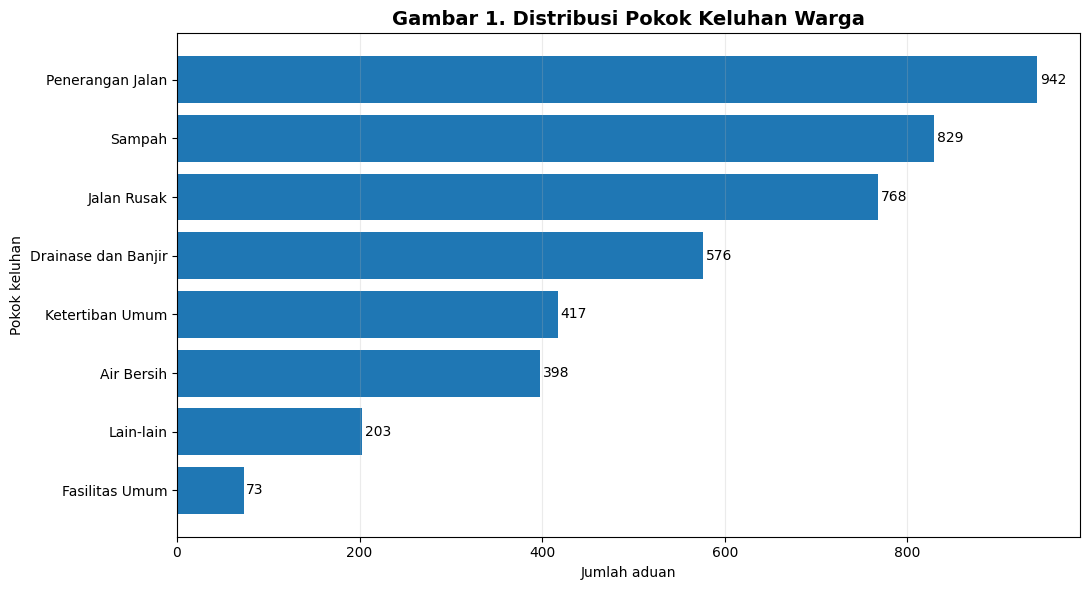


HASIL DISIMPAN DI:
/content/Tugas3-Visualisasi-Data-Teks/outputs/tables
/content/Tugas3-Visualisasi-Data-Teks/outputs/figures


In [84]:

# ============================================================
# BAGIAN B.1 - IDENTIFIKASI POKOK KELUHAN WARGA
# METODE: KEYWORD-BASED CLASSIFICATION
# ============================================================

import os
import re
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PERSIAPAN DATA
# ------------------------------------------------------------

assert "aduan_df" in globals(), "Dataset aduan_df tidak ditemukan."

df_b1 = aduan_df.copy().reset_index(drop=True)

# Gunakan teks yang sudah dimasking jika tersedia
kolom_teks = (
    "teks_aman" if "teks_aman" in df_b1.columns
    else "isi_aduan"
)

df_b1["teks_analisis"] = (
    df_b1[kolom_teks]
    .fillna("")
    .astype(str)
    .str.lower()
)

# ------------------------------------------------------------
# 2. ATURAN IDENTIFIKASI POKOK MASALAH
# ------------------------------------------------------------

aturan = {
    "Air Bersih": [
        r"\bair pdam\b",
        r"\bair bersih\b",
        r"\bair keruh\b",
        r"\bair berbau\b",
        r"\baliran air kecil\b",
        r"\bair tidak mengalir\b",
        r"\bair mati total\b",
        r"\bdistribusi air\b"
    ],

    "Drainase dan Banjir": [
        r"\bdrainase\b",
        r"\bsaluran air\b",
        r"\bsaluran drainase\b",
        r"\bgorong.?gorong\b",
        r"\bbanjir\b",
        r"\bgenangan\b",
        r"\bair menggenang\b",
        r"\bselokan\b",
        r"\bsaluran tersumbat\b"
    ],

    "Penerangan Jalan": [
        r"\blampu jalan\b",
        r"\blampu pju\b",
        r"\bpenerangan jalan\b",
        r"\bjalan gelap\b",
        r"\btiang lampu\b",
        r"\blampu mati\b"
    ],

    "Sampah": [
        r"\bsampah\b",
        r"\bbak sampah\b",
        r"\btps\b",
        r"\btumpukan sampah\b",
        r"\bsampah menumpuk\b",
        r"\bsampah berserakan\b",
        r"\bsampah meluber\b"
    ],

    "Jalan Rusak": [
        r"\bjalan berlubang\b",
        r"\bjalan rusak\b",
        r"\blubang jalan\b",
        r"\baspal mengelupas\b",
        r"\baspal rusak\b",
        r"\bjalan retak\b",
        r"\bjalan berbatu\b"
    ],

    "Ketertiban Umum": [
        r"\bpedagang kaki lima\b",
        r"\bpkl\b",
        r"\bparkir liar\b",
        r"\bkendaraan parkir\b",
        r"\bparkir sembarangan\b",
        r"\bparkir di trotoar\b",
        r"\bberjualan di trotoar\b",
        r"\bsuara bising\b",
        r"\bkebisingan\b"
    ],

    "Fasilitas Umum": [
        r"\btrotoar rusak\b",
        r"\btrotoar berlubang\b",
        r"\bpohon lapuk\b",
        r"\bpohon tumbang\b",
        r"\bpohon miring\b",
        r"\bkabel listrik menjuntai\b",
        r"\bfasilitas umum\b",
        r"\btaman rusak\b"
    ],

    "Lain-lain": [
        r"\blimbah\b",
        r"\bpencemaran\b",
        r"\bbau menyengat\b",
        r"\bhewan liar\b"
    ]
}

# ------------------------------------------------------------
# 3. KLASIFIKASI BERDASARKAN KECocOKAN KATA KUNCI
# ------------------------------------------------------------

def klasifikasi_keluhan(teks):

    if not teks.strip():
        return pd.Series({
            "pokok_masalah": "Teks kosong",
            "kata_kunci": "",
            "jumlah_kategori_terdeteksi": 0,
            "status_klasifikasi": "Tidak dapat diklasifikasikan"
        })

    skor = {}
    kata_ditemukan = {}

    for kategori, pola_list in aturan.items():
        temuan = []

        for pola in pola_list:
            hasil = re.findall(pola, teks)

            if hasil:
                temuan.extend(hasil)

        if temuan:
            skor[kategori] = len(temuan)
            kata_ditemukan[kategori] = list(set(temuan))

    # Tidak ditemukan kata kunci
    if not skor:
        return pd.Series({
            "pokok_masalah": "Belum teridentifikasi",
            "kata_kunci": "",
            "jumlah_kategori_terdeteksi": 0,
            "status_klasifikasi": "Perlu pemeriksaan"
        })

    # Urutkan kategori berdasarkan skor
    urutan = sorted(
        skor.items(),
        key=lambda x: x[1],
        reverse=True
    )

    kategori_teratas = urutan[0][0]
    skor_teratas = urutan[0][1]

    # Jika ada dua kategori dengan skor tertinggi yang sama,
    # tandai untuk pemeriksaan agar tidak memaksakan klasifikasi.
    if len(urutan) > 1 and urutan[1][1] == skor_teratas:
        return pd.Series({
            "pokok_masalah": "Perlu pemeriksaan manual",
            "kata_kunci": ", ".join(skor.keys()),
            "jumlah_kategori_terdeteksi": len(skor),
            "status_klasifikasi": "Ambigu"
        })

    return pd.Series({
        "pokok_masalah": kategori_teratas,
        "kata_kunci": ", ".join(
            kata_ditemukan[kategori_teratas]
        ),
        "jumlah_kategori_terdeteksi": len(skor),
        "status_klasifikasi": (
            "Satu kategori terdeteksi"
            if len(skor) == 1
            else "Kategori dengan kecocokan tertinggi"
        )
    })

hasil_klasifikasi = df_b1["teks_analisis"].apply(
    klasifikasi_keluhan
)

df_b1 = pd.concat(
    [df_b1, hasil_klasifikasi],
    axis=1
)

# ------------------------------------------------------------
# 4. HITUNG DISTRIBUSI POKOK KELUHAN
# ------------------------------------------------------------

rekap_b1 = (
    df_b1["pokok_masalah"]
    .value_counts()
    .rename_axis("Pokok keluhan")
    .reset_index(name="Jumlah aduan")
)

rekap_b1["Persentase"] = (
    rekap_b1["Jumlah aduan"] / len(df_b1) * 100
).round(2)

# ------------------------------------------------------------
# 5. TAMPILKAN CONTOH ADUAN SETIAP KATEGORI
# ------------------------------------------------------------

contoh_b1 = (
    df_b1.groupby("pokok_masalah", group_keys=False)
    .head(3)
)

kolom_contoh = [
    kolom for kolom in [
        "id_aduan",
        "kategori_dilaporkan",
        "pokok_masalah",
        "teks_analisis",
        "kata_kunci",
        "status_klasifikasi"
    ]
    if kolom in contoh_b1.columns
]

# ------------------------------------------------------------
# 6. VISUALISASI GAMBAR 1
# ------------------------------------------------------------

rekap_grafik = rekap_b1[
    ~rekap_b1["Pokok keluhan"].isin([
        "Teks kosong",
        "Belum teridentifikasi",
        "Perlu pemeriksaan manual"
    ])
].sort_values("Jumlah aduan", ascending=True)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    rekap_grafik["Pokok keluhan"],
    rekap_grafik["Jumlah aduan"]
)

plt.title(
    "Gambar 1. Distribusi Pokok Keluhan Warga",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Jumlah aduan")
plt.ylabel("Pokok keluhan")
plt.grid(axis="x", alpha=0.25)

for bar in bars:
    nilai = int(bar.get_width())
    plt.text(
        nilai + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{nilai:,}",
        va="center"
    )

plt.tight_layout()

# ------------------------------------------------------------
# 7. SIMPAN HASIL KE REPOSITORY
# ------------------------------------------------------------

TABLE_DIR = os.path.join(OUTPUT_DIR, "tables")
FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")

os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

df_b1.to_csv(
    os.path.join(TABLE_DIR, "hasil_klasifikasi_pokok_keluhan.csv"),
    index=False,
    encoding="utf-8-sig"
)

rekap_b1.to_csv(
    os.path.join(TABLE_DIR, "distribusi_pokok_keluhan.csv"),
    index=False,
    encoding="utf-8-sig"
)

plt.savefig(
    os.path.join(FIGURE_DIR, "gambar_1_distribusi_pokok_keluhan.png"),
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 8. TAMPILKAN HASIL
# ------------------------------------------------------------

print("HASIL IDENTIFIKASI POKOK KELUHAN")
print("Total aduan:", len(df_b1))

print("\nDISTRIBUSI POKOK KELUHAN:")
display(rekap_b1)

print("\nJUMLAH ADUAN YANG PERLU DIPERIKSA:")
print(
    df_b1["status_klasifikasi"]
    .isin(["Perlu pemeriksaan", "Ambigu"])
    .sum()
)

print("\nCONTOH ADUAN SETIAP KELOMPOK:")
with pd.option_context("display.max_colwidth", None):
    display(contoh_b1[kolom_contoh])

print("\nVISUALISASI:")
plt.show()

print("\nHASIL DISIMPAN DI:")
print(TABLE_DIR)
print(FIGURE_DIR)


## B.1.a - DIAGNOSTIK ADUAN BELUM TERIDENTIFIKASI

In [85]:

# ============================================================
# BAGIAN B.1 - DIAGNOSTIK ADUAN BELUM TERIDENTIFIKASI
# ============================================================

from collections import Counter
import re

# Ambil seluruh aduan yang belum teridentifikasi
data_belum = df_b1[
    df_b1["pokok_masalah"] == "Belum teridentifikasi"
].copy()

# Hitung frekuensi kata pada teks
semua_kata = []

for teks in data_belum["teks_analisis"].fillna(""):
    kata = re.findall(r"\b[a-z]{3,}\b", teks)
    semua_kata.extend(kata)

frekuensi_kata = pd.DataFrame(
    Counter(semua_kata).most_common(40),
    columns=["Kata", "Frekuensi"]
)

# Ambil 30 contoh aduan untuk diperiksa
contoh_belum = data_belum[
    [
        "id_aduan",
        "kategori_dilaporkan",
        "teks_analisis"
    ]
].head(30)

print("JUMLAH ADUAN BELUM TERIDENTIFIKASI:",
      len(data_belum))

print("\n40 KATA PALING SERING MUNCUL:")
display(frekuensi_kata)

print("\n30 CONTOH ADUAN:")
with pd.option_context("display.max_colwidth", None):
    display(contoh_belum)


JUMLAH ADUAN BELUM TERIDENTIFIKASI: 836

40 KATA PALING SERING MUNCUL:


,Kata,Frekuensi
0,mohon,724
1,ibu,676
2,kasih,651
3,terima,649
4,bapak,609
5,jalan,496
6,saya,312
7,sudah,287
8,segera,285
9,lokasi,270



30 CONTOH ADUAN:


,id_aduan,kategori_dilaporkan,teks_analisis
20,ADU-000069,Jalan Rusak,"selamat pagi bapak/ibu, lubang besar di komplek taman asih membuat pengendara motor terjatuh. lokasi persisnya di seberang gerbang, dekat tiang listrik. kami mohon maaf apabila laporan ini berulang. atas perhatian bapak/ibu saya ucapkan terima kasih."
22,ADU-004112,Jalan Rusak,"assalamualaikum bapak/ibu, lubang besar di jalan kopo hilir membuat pengendara motor terjatuh. banyak anak sekolah melewati lokasi ini setiap hari. demikian aduan saya, terima kasih banyak."
23,ADU-002742,Jalan Rusak,aspal jalan mengelupas sepanjang komplek pondok hijau. mohon segera ditindaklanjuti. terima kasih.
25,ADU-000501,Fasilitas Umum,"kepada bapak/ibu petugas yang bertugas, trotoar di jalan sukamaju dalam rusak dan berlubang sehingga tidak bisa dilewati. kondisi ini sudah dilaporkan ke rw tetapi belum ada tindakan. kami mohon segera diperbaiki. terima kasih sebelumnya."
27,ADU-002842,Fasilitas Umum,"yth. bapak/ibu wali kota, perjalanan anak ke sekolah jadi lama karena trotoar di komplek pondok hijau rusak. sebelumnya terima kasih atas perhatian bapak/ibu. mohon ditindaklanjuti segera karena sudah mengganggu warga. terima kasih."
33,ADU-003211,Lain-lain,aaa
37,ADU-001096,Jalan Rusak,"punten bapa/ibu, lubang besar di perumahan bumi lestari membuat pengendara motor terjatuh. banyak anak sekolah melewati lokasi ini setiap hari. hatur nuhun kana perhatosanana."
39,ADU-002584,Fasilitas Umum,"assalamualaikum bapak/ibu, trotoar di jalan kopo hilir rusak dan berlubang sehingga tidak bisa dilewati. mohon ditindaklanjuti segera karena sudah mengganggu warga. terima kasih. nomor saya [telepon disamarkan] bisa dihubungi."
44,ADU-000187,Fasilitas Umum,pohon besar di jalan dahlia ujung miring dan hampir tumbang ke badan jalan.
49,ADU-002739,Jalan Rusak,"yth. bapak/ibu wali kota, aspal jalan mengelupas sepanjang perumahan griya asri. kami mohon segera diperbaiki. terima kasih sebelumnya."


## B.1.b - PERBAIKAN IDENTIFIKASI POKOK KELUHAN

In [86]:

# ============================================================
# BAGIAN B.1 - PERBAIKAN IDENTIFIKASI POKOK KELUHAN
# ============================================================

import re
import pandas as pd

# Salin data agar hasil klasifikasi sebelumnya tetap tersedia
df_b1_revisi = df_b1.copy()

# Pastikan teks tidak kosong
df_b1_revisi["teks_analisis"] = (
    df_b1_revisi["teks_analisis"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)

# Aturan klasifikasi berdasarkan masalah utama
aturan_keluhan = [
    (
        "Penerangan Jalan",
        r"\b(lampu pju|lampu jalan|penerangan jalan|"
        r"lampu penerangan|lampu umum)\b"
    ),
    (
        "Sampah",
        r"\b(sampah|tps|tempat pembuangan sampah|"
        r"bak sampah|tempat sampah)\b"
    ),
    (
        "Jalan Rusak",
        r"\b(jalan berlubang|lubang besar|jalan rusak|"
        r"aspal jalan mengelupas|aspal mengelupas|"
        r"jalan bergelombang|jalan retak|jalan berbatu)\b"
    ),
    (
        "Drainase dan Banjir",
        r"\b(banjir|drainase|gorong.gorong|"
        r"saluran air|air menggenang|saluran tersumbat)\b"
    ),
    (
        "Ketertiban Umum",
        r"\b(parkir liar|kendaraan parkir|angkutan berhenti|"
        r"berhenti sembarangan|suara bising|"
        r"pedagang kaki lima|pkl)\b"
    ),
    (
        "Air Bersih",
        r"\b(air pdam|air keruh|air bersih|"
        r"air tidak mengalir|air mati|aliran air kecil|"
        r"air berbau)\b"
    ),
    (
        "Fasilitas Umum",
        r"\b(trotoar|pohon besar|pohon tumbang|"
        r"hampir tumbang|kabel listrik menjuntai|"
        r"kabel menjuntai|fasilitas umum)\b"
    ),
    (
        "Lain-lain",
        r"\b(limbah|pencemaran|polusi)\b"
    )
]

# Identifikasi teks yang benar-benar tidak informatif
pola_tidak_informatif = [
    r"^$",
    r"^-+$",
    r"^aaa+$",
    r"^halo$",
    r"^test$",
    r"^tes$"
]

def klasifikasi_perbaikan(teks):
    teks = str(teks).strip().lower()

    if any(re.fullmatch(p, teks) for p in pola_tidak_informatif):
        return "Belum teridentifikasi"

    # Periksa aturan berdasarkan prioritas
    for kategori, pola in aturan_keluhan:
        if re.search(pola, teks):
            return kategori

    return "Belum teridentifikasi"


# Perbaiki seluruh baris berdasarkan isi teks,
# bukan hanya berdasarkan kategori yang dilaporkan
df_b1_revisi["pokok_masalah_revisi"] = (
    df_b1_revisi["teks_analisis"].apply(klasifikasi_perbaikan)
)

# Rekapitulasi hasil
rekap_b1_revisi = (
    df_b1_revisi["pokok_masalah_revisi"]
    .value_counts()
    .rename_axis("Pokok keluhan")
    .reset_index(name="Jumlah aduan")
)

rekap_b1_revisi["Persentase"] = (
    rekap_b1_revisi["Jumlah aduan"] /
    len(df_b1_revisi) * 100
).round(2)

print("HASIL PERBAIKAN IDENTIFIKASI POKOK KELUHAN")
print("Total aduan:", len(df_b1_revisi))

print("\nDISTRIBUSI POKOK KELUHAN:")
display(rekap_b1_revisi)

print("\nJUMLAH ADUAN BELUM TERIDENTIFIKASI:",
      (df_b1_revisi["pokok_masalah_revisi"] ==
       "Belum teridentifikasi").sum())

# Periksa contoh yang masih belum teridentifikasi
print("\nCONTOH ADUAN YANG MASIH BELUM TERIDENTIFIKASI:")
display(
    df_b1_revisi.loc[
        df_b1_revisi["pokok_masalah_revisi"] ==
        "Belum teridentifikasi",
        ["id_aduan", "kategori_dilaporkan", "teks_analisis"]
    ].head(20)
)


HASIL PERBAIKAN IDENTIFIKASI POKOK KELUHAN
Total aduan: 5049

DISTRIBUSI POKOK KELUHAN:


,Pokok keluhan,Jumlah aduan,Persentase
0,Jalan Rusak,1123,22.24
1,Penerangan Jalan,942,18.66
2,Sampah,829,16.42
3,Drainase dan Banjir,576,11.41
4,Ketertiban Umum,514,10.18
5,Air Bersih,398,7.88
6,Fasilitas Umum,305,6.04
7,Lain-lain,202,4.00
8,Belum teridentifikasi,160,3.17



JUMLAH ADUAN BELUM TERIDENTIFIKASI: 160

CONTOH ADUAN YANG MASIH BELUM TERIDENTIFIKASI:


,id_aduan,kategori_dilaporkan,teks_analisis
33,ADU-003211,Lain-lain,aaa
120,ADU-003019,Sampah,-
154,ADU-000669,Ketertiban Umum,halo
197,ADU-004501,Ketertiban Umum,"assalamualaikum bapak/ibu, kendaraan parkiir di badan jalan depan gang melati menyebabkan macet ..."
307,ADU-003803,Air Bersih,tes
316,ADU-004407,Penerangan Jalan,aaa
342,ADU-004831,Sampah,"yth. dinas terkait, pohon di depan puskesmas kelurahan sudah lapuk dan mengkhawatirkan. lokasi p..."
372,ADU-000485,Air Bersih,coba
473,ADU-004527,Air Bersih,?
492,ADU-001698,Sampah,"wilujeng enjing bapa/ibu, saampah berserakan di depan kantor kelurahan sampai ke badan jalan. ma..."


## B.1.c - PENYEMPURNAAN NORMALISASI DAN KLASIFIKASI

In [87]:

# ============================================================
# BAGIAN B.1 - PENYEMPURNAAN NORMALISASI DAN KLASIFIKASI
# ============================================================

import re
import pandas as pd

# Salin data agar dataset awal tetap aman
df_b1_final = df_b1.copy()

# Normalisasi khusus untuk menangani huruf berulang,
# misalnya parkiir -> parkir, saampah -> sampah
def normalisasi_kata(teks):
    teks = str(teks).lower().strip()
    teks = re.sub(r"(.)\1+", r"\1", teks)
    teks = re.sub(r"\s+", " ", teks)
    return teks

df_b1_final["teks_normalisasi_b1"] = (
    df_b1_final["teks_analisis"]
    .fillna("")
    .apply(normalisasi_kata)
)

# Teks yang tidak memiliki informasi keluhan
teks_tidak_informatif = {
    "", "-", "?", "aaa", "halo", "test", "tes", "coba"
}

# Aturan klasifikasi berdasarkan isi aduan
aturan_final = [
    (
        "Penerangan Jalan",
        r"\b(lampu pju|lampu jalan|penerangan jalan|"
        r"lampu penerangan|lampu umum|jalan gelap)\b"
    ),
    (
        "Sampah",
        r"\b(sampah|tps|tempat pembuangan sampah|"
        r"bak sampah|tempat sampah)\b"
    ),
    (
        "Drainase dan Banjir",
        r"\b(banjir|drainase|gorong.gorong|"
        r"saluran air|air menggenang|saluran tersumbat)\b"
    ),
    (
        "Ketertiban Umum",
        r"\b(parkir liar|kendaraan parkir|angkutan berhenti|"
        r"berhenti sembarangan|suara bising|"
        r"pedagang kaki lima|pkl)\b"
    ),
    (
        "Air Bersih",
        r"\b(air pdam|air keruh|air bersih|"
        r"air tidak mengalir|air mati|aliran air kecil|"
        r"air berbau)\b"
    ),
    (
        "Fasilitas Umum",
        r"\b(trotoar|pohon besar|pohon lapuk|"
        r"pohon tumbang|hampir tumbang|"
        r"kabel listrik menjuntai|kabel menjuntai|"
        r"fasilitas umum)\b"
    ),
    (
        "Jalan Rusak",
        r"\b(jalan berlubang|lubang besar|"
        r"jalan rusak|aspal jalan mengelupas|"
        r"aspal mengelupas|jalan bergelombang|"
        r"jalan retak|jalan berbatu)\b"
    ),
    (
        "Lain-lain",
        r"\b(limbah|pencemaran|polusi)\b"
    )
]

def klasifikasi_final(teks):
    teks = normalisasi_kata(teks)

    if teks in teks_tidak_informatif:
        return "Belum teridentifikasi"

    for kategori, pola in aturan_final:
        if re.search(pola, teks):
            return kategori

    return "Belum teridentifikasi"


# Terapkan pada seluruh dataset
df_b1_final["pokok_masalah_final"] = (
    df_b1_final["teks_normalisasi_b1"]
    .apply(klasifikasi_final)
)

# Rekapitulasi
rekap_final_b1 = (
    df_b1_final["pokok_masalah_final"]
    .value_counts()
    .rename_axis("Pokok keluhan")
    .reset_index(name="Jumlah aduan")
)

rekap_final_b1["Persentase"] = (
    rekap_final_b1["Jumlah aduan"] /
    len(df_b1_final) * 100
).round(2)

belum_final = df_b1_final[
    df_b1_final["pokok_masalah_final"] ==
    "Belum teridentifikasi"
].copy()

print("HASIL PENYEMPURNAAN KLASIFIKASI")
print("Total aduan:", len(df_b1_final))
print("Berhasil diklasifikasikan:",
      len(df_b1_final) - len(belum_final))
print("Belum teridentifikasi:", len(belum_final))

print("\nDISTRIBUSI POKOK KELUHAN:")
display(rekap_final_b1)

print("\nCONTOH ADUAN YANG MASIH BELUM TERIDENTIFIKASI:")
with pd.option_context("display.max_colwidth", None):
    display(
        belum_final[
            ["id_aduan", "kategori_dilaporkan",
             "teks_analisis"]
        ].head(30)
    )


HASIL PENYEMPURNAAN KLASIFIKASI
Total aduan: 5049
Berhasil diklasifikasikan: 4674
Belum teridentifikasi: 375

DISTRIBUSI POKOK KELUHAN:


,Pokok keluhan,Jumlah aduan,Persentase
0,Jalan Rusak,1129,22.36
1,Penerangan Jalan,947,18.76
2,Sampah,834,16.52
3,Drainase dan Banjir,466,9.23
4,Air Bersih,399,7.90
5,Ketertiban Umum,396,7.84
6,Belum teridentifikasi,375,7.43
7,Fasilitas Umum,301,5.96
8,Lain-lain,202,4.00



CONTOH ADUAN YANG MASIH BELUM TERIDENTIFIKASI:


,id_aduan,kategori_dilaporkan,teks_analisis
4,ADU-001236,Ketertiban Umum,"mohon perhatiannya, kendaraan parkir di badan jalan depan gang melati menyebabkan macet panjang. mohon segera ditindaklanjuti. terima kasih."
14,ADU-002263,Penerangan Jalan,"mohon perhatiannya, air menggenang berhari-hari di gang mawar dalam setelah hujan. kami mohon maaf apabila laporan ini berulang. mohon ditindaklanjuti segera karena sudah mengganggu warga. terima kasih."
33,ADU-003211,Lain-lain,aaa
40,ADU-003346,Penerangan Jalan,"kendaraan parkir di badan jalan depan perumahan bumi lestari menyebabkan macet panjang. warga sudah beberapa kali menegur namun tidak digubris. mangga ditingali heula ka lokasi. mangga dipiharep enggal ditindaklanjuti, hatur nuhun."
41,ADU-001062,Ketertiban Umum,"yth. dinas terkait, air menggenang berhari-hari di gang kenanga setelah hujan. warga sudah beberapa kali menegur namun tidak digubris. mohon ditindaklanjuti segera karena sudah mengganggu warga. terima kasih."
45,ADU-002708,Drainase dan Banjir,"yth. bapak/ibu wali kota, air menggenang berhari-hari di jalan dahlia ujung setelah hujan. mohon ditindaklanjuti segera karena sudah mengganggu warga. terima kasih."
48,ADU-004050,Ketertiban Umum,"mohon perhatiannya, kendaraan parkir di badan jalan depan perumahan griya asri menyebabkan macet panjang. mohon petugas datang meninjau langsung ke lokasi. mohon bantuannya ya pak, terima kasih."
120,ADU-003019,Sampah,-
125,ADU-001363,Ketertiban Umum,"mohon bantuan bapak/ibu, kendaraan parkir di badan jalan depan gang mawar dalam menyebabkan macet panjang. sebelumnya terima kasih atas perhatian bapak/ibu. mohon segera ditindaklanjuti. terima kasih."
127,ADU-000349,Drainase dan Banjir,"yth. bapak/ibu wali kota, air menggenang berhari-hari di gang melati setelah hujan. mohon bantuannya ya pak, terima kasih."


## B.1.d - PERBAIKAN FINAL ATURAN KLASIFIKASI

In [88]:

# ============================================================
# BAGIAN B.1 - PENYEMPURNAAN ATURAN KLASIFIKASI
# ============================================================

import re
import pandas as pd

aturan_final = [
    ("Penerangan Jalan", [
        r"\blampu.{0,25}jal+a+n\b",
        r"\bpenerangan jalan\b",
        r"\bjalan gelap\b",
        r"\btiang lampu\b",
        r"\bpju\b"
    ]),

    ("Sampah", [
        r"\bsa+mpah\b",
        r"\bbak sampah\b",
        r"\btempat sampah\b",
        r"\btps\b"
    ]),

    ("Jalan Rusak", [
        r"\bjalan berlubang+\b",
        r"\blubang besar\b",
        r"\blubang besaar\b",
        r"\bjalan rusak\b",
        r"\baspal.{0,60}(rusak|mengelupas+)\b",
        r"\bjalan retak\b",
        r"\bjalan berbatu\b",
        r"\bjalan bergelombang\b"
    ]),

    ("Drainase dan Banjir", [
        r"\bbanjir\b",
        r"\bdrainase\b",
        r"\bgorong.gorong\b",
        r"\bsaluran air\b",
        r"\bair menggenang\b",
        r"\bgenangan\b",
        r"\bselokan\b",
        r"\bsaluran tersumbat\b"
    ]),

    ("Ketertiban Umum", [
        r"\bkendaraan park+i+r\b",
        r"\bparkir liar\b",
        r"\bparkir sembarangan\b",
        r"\bangkutan berhenti\b",
        r"\bberhenti sembarangan\b",
        r"\bpedagang kaki lima\b",
        r"\bpkl\b",
        r"\bsuara bising\b",
        r"\bkebisingan\b"
    ]),

    ("Air Bersih", [
        r"\bair pdam\b",
        r"\bair keruh\b",
        r"\bair bersih\b",
        r"\bair tidak mengalir\b",
        r"\bair mati\b",
        r"\baliran air kecil\b",
        r"\bair berbau\b"
    ]),

    ("Fasilitas Umum", [
        r"\bpohon.{0,100}(lapuk|tumbang|miring|hampir tumbang)\b",
        r"\bpohon.{0,100}mengkhawatirkan\b",
        r"\btrotoar\b",
        r"\bkabel.{0,40}menjuntai\b",
        r"\bfasilitas umum\b",
        r"\btaman rusak\b"
    ]),

    ("Lain-lain", [
        r"\blimbah\b",
        r"\bpencemaran\b",
        r"\bpolusi\b"
    ])
]

teks_tidak_informatif = {
    "", "-", "?", ".", "aaa", "halo",
    "test", "tes", "coba", "tes aja",
    "test kirim"
}

def klasifikasi_b1(teks):
    teks = str(teks).strip().lower()

    if teks in teks_tidak_informatif:
        return "Tidak dapat diklasifikasikan"

    for kategori, daftar_pola in aturan_final:
        for pola in daftar_pola:
            if re.search(pola, teks):
                return kategori

    return "Belum teridentifikasi"


# Klasifikasi ulang seluruh data
df_b1_final["pokok_masalah_final"] = (
    df_b1_final["teks_analisis"].apply(klasifikasi_b1)
)

# Rekapitulasi
rekap_final_b1 = (
    df_b1_final["pokok_masalah_final"]
    .value_counts()
    .rename_axis("Pokok keluhan")
    .reset_index(name="Jumlah aduan")
)

rekap_final_b1["Persentase"] = (
    rekap_final_b1["Jumlah aduan"] /
    len(df_b1_final) * 100
).round(2)

print("HASIL KLASIFIKASI TERBARU")
print("Total aduan:", len(df_b1_final))
display(rekap_final_b1)

# Periksa apakah contoh yang sebelumnya terlewat sudah tertangkap
contoh_periksa = df_b1_final[
    df_b1_final["id_aduan"].isin([
        "ADU-003131",
        "ADU-004831",
        "ADU-000061",
        "ADU-004313",
        "ADU-003001"
    ])
][[
    "id_aduan",
    "teks_analisis",
    "pokok_masalah_final"
]]

print("\nPEMERIKSAAN CONTOH KASUS:")
with pd.option_context("display.max_colwidth", None):
    display(contoh_periksa)

print("\nBelum teridentifikasi:",
      (df_b1_final["pokok_masalah_final"] ==
       "Belum teridentifikasi").sum())

print("Tidak dapat diklasifikasikan:",
      (df_b1_final["pokok_masalah_final"] ==
       "Tidak dapat diklasifikasikan").sum())


HASIL KLASIFIKASI TERBARU
Total aduan: 5049


,Pokok keluhan,Jumlah aduan,Persentase
0,Jalan Rusak,1126,22.30
1,Penerangan Jalan,946,18.74
2,Sampah,833,16.50
3,Drainase dan Banjir,576,11.41
4,Ketertiban Umum,515,10.20
5,Air Bersih,398,7.88
6,Fasilitas Umum,374,7.41
7,Lain-lain,202,4.00
8,Tidak dapat diklasifikasikan,62,1.23
9,Belum teridentifikasi,17,0.34



PEMERIKSAAN CONTOH KASUS:


,id_aduan,teks_analisis,pokok_masalah_final
331,ADU-003131,"yth. dinas terkait, pohon besar di komplek pondok hijau miring dan hampir tumbang ke badan jalan. mohon petugas datang meninjau langsung ke lokasi. atas perhatian bapak/ibu saya ucapkan terima kasih.",Fasilitas Umum
342,ADU-004831,"yth. dinas terkait, pohon di depan puskesmas kelurahan sudah lapuk dan mengkhawatirkan. lokasi persisnya di seberang gerbang, dekat tiang listrik. mohon segera ditindaklanjuti. terima kasih.",Fasilitas Umum
590,ADU-000061,"punten bapa/ibu, pohon di depan warung bu enok sudah lapuk dan mengkhawatirkan. banyak anak sekolah melewati lokasi ini setiap hari. mangga dipiharep enggal ditindaklanjuti, hatur nuhun.",Fasilitas Umum
940,ADU-004313,"kepada bapak/ibu petugas yang bertugas, lampu jalaaan di komplek pondok hijau mati sehingga rawan copet padaa malam hari. mohon bantuannya ya pak, terima kasih.",Penerangan Jalan
987,ADU-003001,"selamat siang, saya warga di lokasi berikut, aspal jalan mengelupasss sepanjang jalan cendana raaaya. atas perhatian bapak/ibu saya ucapkan terima kasih.",Jalan Rusak



Belum teridentifikasi: 17
Tidak dapat diklasifikasikan: 62


In [89]:

# ============================================================
# BAGIAN B.1 - PEMERIKSAAN 17 ADUAN BELUM TERIDENTIFIKASI
# ============================================================

kasus_tersisa = df_b1_final[
    df_b1_final["pokok_masalah_final"] == "Belum teridentifikasi"
].copy()

print("Jumlah aduan yang belum teridentifikasi:", len(kasus_tersisa))

kolom_tinjauan = [
    "id_aduan",
    "kategori_dilaporkan",
    "teks_analisis"
]

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None
):
    display(kasus_tersisa[kolom_tinjauan])


Jumlah aduan yang belum teridentifikasi: 17


,id_aduan,kategori_dilaporkan,teks_analisis
1674,ADU-000046,Jalan Rusak,"selamat pagi bapak/ibu, jalan berlubaaaang di jalan bukit indah mengganggu perjalanan warga setiiiap pagi. banyak anak sekolah melewati lokasi ini setiap hari. demikian aduan saya, terima kasih banyak."
1894,ADU-004240,Jalan Rusak,asdf
2252,ADU-004125,Lain-lain,"kepada bapak/ibu petugas yang bertugas, suaraa bising dari bengkel di jalan bukit indah sampaai tengah malam. mohon kiranya dapat menjadi perhatian."
2472,ADU-003754,Penerangan Jalan,"mohon perhatiannya, jalanan gelap total karena laampu jalan mati di jalan bukit indah. sudah ada dua orang yang jatuh di lokasi tersebut. atas perhatian bapak/ibu saya ucapkan teeerima kasih."
2965,ADU-003730,Drainase dan Banjir,123
2986,ADU-004722,Ketertiban Umum,"wilujeng enjing bapa/ibu, air menggenaang berhari-hari di jalan bukit indah setelah hujan. hatur nuhun kana perhatosanana."
3010,ADU-003159,Sampah,asdf
3012,ADU-005007,Jalan Rusak,123
3247,ADU-001278,Air Bersih,"mohon bantuan bapak/ibu, air tiiidak mengalir sejak pagi di daerah pasar rakyat. sudah ada dua orang yang jatuh di lokasi tersebut. atas perhatian bapak/ibu saya ucapkan terima kasih."
3459,ADU-003301,Lain-lain,asdf


In [90]:
# ============================================================
# FINALISASI 17 ADUAN YANG BELUM TERIDENTIFIKASI
# ============================================================

keputusan_manual = {
    "ADU-000046": "Jalan Rusak",
    "ADU-004240": "Tidak dapat diklasifikasikan",
    "ADU-004125": "Ketertiban Umum",
    "ADU-003754": "Penerangan Jalan",
    "ADU-003730": "Tidak dapat diklasifikasikan",
    "ADU-004722": "Drainase dan Banjir",
    "ADU-003159": "Tidak dapat diklasifikasikan",
    "ADU-005007": "Tidak dapat diklasifikasikan",
    "ADU-001278": "Air Bersih",
    "ADU-003301": "Tidak dapat diklasifikasikan",
    "ADU-001566": "Tidak dapat diklasifikasikan",
    "ADU-004082": "Ketertiban Umum",
    "ADU-000099": "Jalan Rusak",
    "ADU-004278": "Sampah",
    "ADU-002335": "Tidak dapat diklasifikasikan",
    "ADU-002706": "Jalan Rusak",
    "ADU-001474": "Tidak dapat diklasifikasikan"
}

# Terapkan keputusan manual
df_b1_final["pokok_masalah_final"] = df_b1_final.apply(
    lambda row: keputusan_manual.get(
        row["id_aduan"],
        row["pokok_masalah_final"]
    ),
    axis=1
)

# Tampilkan distribusi terbaru
rekap_b1_final = (
    df_b1_final["pokok_masalah_final"]
    .value_counts()
    .rename_axis("Pokok Masalah")
    .reset_index(name="Jumlah Aduan")
)

rekap_b1_final["Persentase (%)"] = (
    rekap_b1_final["Jumlah Aduan"] /
    len(df_b1_final) * 100
).round(2)

print("TOTAL ADUAN:", len(df_b1_final))
print("TOTAL HASIL KLASIFIKASI:",
      df_b1_final["pokok_masalah_final"].notna().sum())

display(rekap_b1_final)

print("\nJumlah aduan yang belum teridentifikasi:",
      (df_b1_final["pokok_masalah_final"] ==
       "Belum teridentifikasi").sum())

print("Jumlah aduan yang tidak dapat diklasifikasikan:",
      (df_b1_final["pokok_masalah_final"] ==
       "Tidak dapat diklasifikasikan").sum())

TOTAL ADUAN: 5049
TOTAL HASIL KLASIFIKASI: 5049


,Pokok Masalah,Jumlah Aduan,Persentase (%)
0,Jalan Rusak,1129,22.36
1,Penerangan Jalan,947,18.76
2,Sampah,834,16.52
3,Drainase dan Banjir,577,11.43
4,Ketertiban Umum,517,10.24
5,Air Bersih,399,7.90
6,Fasilitas Umum,374,7.41
7,Lain-lain,202,4.00
8,Tidak dapat diklasifikasikan,70,1.39



Jumlah aduan yang belum teridentifikasi: 0
Jumlah aduan yang tidak dapat diklasifikasikan: 70


## B1 - VISUALISASI

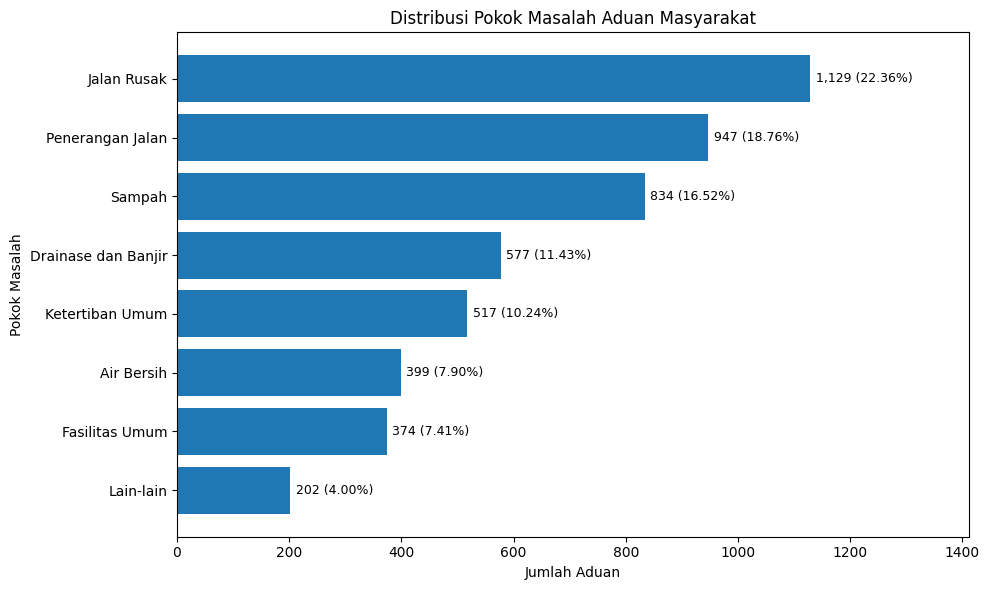

Grafik dan tabel berhasil disimpan.


In [91]:
import matplotlib.pyplot as plt
import os

# Siapkan data visualisasi: keluarkan aduan yang tidak dapat diklasifikasikan
plot_b1 = rekap_b1_final[
    rekap_b1_final["Pokok Masalah"] != "Tidak dapat diklasifikasikan"
].sort_values("Jumlah Aduan", ascending=True)

# Buat grafik
plt.figure(figsize=(10, 6))

bars = plt.barh(
    plot_b1["Pokok Masalah"],
    plot_b1["Jumlah Aduan"]
)

plt.title("Distribusi Pokok Masalah Aduan Masyarakat")
plt.xlabel("Jumlah Aduan")
plt.ylabel("Pokok Masalah")

# Tambahkan jumlah dan persentase pada setiap batang
for bar, (_, row) in zip(bars, plot_b1.iterrows()):
    plt.text(
        bar.get_width() + 10,
        bar.get_y() + bar.get_height() / 2,
        f'{int(row["Jumlah Aduan"]):,} ({row["Persentase (%)"]:.2f}%)',
        va="center",
        fontsize=9
    )

plt.xlim(0, plot_b1["Jumlah Aduan"].max() * 1.25)
plt.tight_layout()

# Simpan grafik
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

plt.savefig(
    os.path.join(OUTPUT_DIR, "visualisasi_distribusi_pokok_masalah.png"),
    dpi=300,
    bbox_inches="tight"
)

# Simpan tabel rekap
rekap_b1_final.to_csv(
    os.path.join(TABLE_DIR, "rekap_distribusi_pokok_masalah.csv"),
    index=False
)

# Simpan hasil klasifikasi setiap aduan
df_b1_final.to_csv(
    os.path.join(TABLE_DIR, "hasil_klasifikasi_pokok_masalah.csv"),
    index=False
)

plt.show()

print("Grafik dan tabel berhasil disimpan.")

In [92]:
# Periksa nama kolom dan tipe data dataset aduan
print("Kolom pada aduan_df:")
display(
    pd.DataFrame({
        "Nama Kolom": aduan_df.columns,
        "Tipe Data": aduan_df.dtypes.astype(str).values
    })
)

print("\nContoh data tanggal:")
display(aduan_df.head(5))

Kolom pada aduan_df:


,Nama Kolom,Tipe Data
0,id_aduan,object
1,tanggal,object
2,kanal,object
3,kelurahan,object
4,kategori_dilaporkan,object
5,isi_aduan,object
6,lon,float64
7,lat,float64
8,status,object
9,teks_normalisasi,object



Contoh data tanggal:


,id_aduan,tanggal,kanal,kelurahan,kategori_dilaporkan,isi_aduan,lon,lat,status,teks_normalisasi,teks_aman,tanggal_parsed
0,ADU-002330,2026-03-16,Datang Langsung,Ciburial,Sampah,"Punten ngaganggu waktosna, Sampah menumpuk di TPS Perumahan Griya Asri tidak diangkut petugas. K...",107.566695,-6.925499,Selesai,"punten ngaganggu waktosna, sampah menumpuk di tps perumahan griya asri tidak diangkut petugas. k...","punten ngaganggu waktosna, sampah menumpuk di tps perumahan griya asri tidak diangkut petugas. k...",2026-03-16
1,ADU-004318,2025-09-12,Web,Sekejati,Ketertiban Umum,"Assalamualaikum Bapak/Ibu, Parkir liar di Jalan Cendana Raya menutup separuh badan jalan. Kami k...",107.614777,-6.915453,Selesai,"assalamualaikum bapak/ibu, parkir liar di jalan cendana raya menutup separuh badan jalan. kami k...","assalamualaikum bapak/ibu, parkir liar di jalan cendana raya menutup separuh badan jalan. kami k...",2025-09-12
2,ADU-001600,2025-10-17,Web,Sekejati,Lain-lain,"Assalamualaikum Bapak/Ibu, Suara bising dari bengkel di Komplek Pondok Hijau sampai tengah malam...",107.618543,-6.912097,Diteruskan,"assalamualaikum bapak/ibu, suara bising dari bengkel di komplek pondok hijau sampai tengah malam...","assalamualaikum bapak/ibu, suara bising dari bengkel di komplek pondok hijau sampai tengah malam...",2025-10-17
3,ADU-003353,2026-08-11,Aplikasi Mobile,Cisaranten,Ketertiban Umum,"Penerangan jalan umum di Gang Kenanga tidak menyala sama sekali. Kumaha atuh Pa, hatur nuhun.",107.611433,-6.928716,Diteruskan,"penerangan jalan umum di gang kenanga tidak menyala sama sekali. kumaha atuh pa, hatur nuhun.","penerangan jalan umum di gang kenanga tidak menyala sama sekali. kumaha atuh pa, hatur nuhun.",2026-08-11
4,ADU-001236,28/05/2026,Surat,Kebon Gedang,Ketertiban Umum,"Mohon perhatiannya, Kendaraan parkir di badan jalan depan Gang Melati menyebabkan macet panjang....",107.591213,-6.910023,Selesai,"mohon perhatiannya, kendaraan parkir di badan jalan depan gang melati menyebabkan macet panjang....","mohon perhatiannya, kendaraan parkir di badan jalan depan gang melati menyebabkan macet panjang....",2026-05-28


## B.2.1 - AUDIT RENTANG WAKTU DATA ADUAN

In [93]:
# ============================================================
# B.2.1 - AUDIT RENTANG WAKTU DATA ADUAN
# ============================================================

# Gunakan tanggal_parsed yang sudah tersedia
df_tanggal = aduan_df.copy()
df_tanggal["tanggal_parsed"] = pd.to_datetime(
    df_tanggal["tanggal_parsed"],
    errors="coerce"
)

# Ringkasan tanggal
print("TOTAL ADUAN:", len(df_tanggal))
print("Tanggal valid:", df_tanggal["tanggal_parsed"].notna().sum())
print("Tanggal tidak valid:", df_tanggal["tanggal_parsed"].isna().sum())
print("Tanggal paling awal:", df_tanggal["tanggal_parsed"].min())
print("Tanggal paling akhir:", df_tanggal["tanggal_parsed"].max())

# Jumlah aduan per bulan
df_tanggal_valid = df_tanggal.dropna(
    subset=["tanggal_parsed"]
).copy()

df_tanggal_valid["bulan"] = (
    df_tanggal_valid["tanggal_parsed"].dt.to_period("M")
)

rekap_bulanan = (
    df_tanggal_valid.groupby("bulan")
    .size()
    .reset_index(name="Jumlah Aduan")
)

rekap_bulanan["Bulan"] = (
    rekap_bulanan["bulan"].astype(str)
)

print("\nJUMLAH ADUAN PER BULAN:")
display(rekap_bulanan[["Bulan", "Jumlah Aduan"]])

# Periksa apakah bulan terakhir merupakan bulan parsial
bulan_terakhir = df_tanggal_valid["tanggal_parsed"].max()
print("\nBulan terakhir dalam dataset:", bulan_terakhir.strftime("%Y-%m"))
#print("Tanggal terakhir tercatat:", bulan_terakhir.strftime("%d-%m-%Y"))

TOTAL ADUAN: 5049
Tanggal valid: 5049
Tanggal tidak valid: 0
Tanggal paling awal: 2025-09-01 00:00:00
Tanggal paling akhir: 2026-08-31 00:00:00

JUMLAH ADUAN PER BULAN:


,Bulan,Jumlah Aduan
0,2025-09,419
1,2025-10,420
2,2025-11,373
3,2025-12,449
4,2026-01,425
5,2026-02,389
6,2026-03,443
7,2026-04,432
8,2026-05,413
9,2026-06,440



Bulan terakhir dalam dataset: 2026-08
Tanggal terakhir tercatat: 31-08-2026


## B.2.2 - ANALISIS TREN BULANAN POKOK MASALAH

JUMLAH ADUAN PER TOPIK SETIAP BULAN


pokok_masalah_final,Air Bersih,Drainase dan Banjir,Fasilitas Umum,Jalan Rusak,Ketertiban Umum,Lain-lain,Penerangan Jalan,Sampah
2025-09,20,51,40,94,50,20,74,66
2025-10,35,39,21,93,47,19,82,77
2025-11,31,51,29,80,34,18,64,62
2025-12,29,44,28,120,39,17,92,75
2026-01,20,38,39,107,36,15,88,73
2026-02,37,43,27,85,36,16,76,62
2026-03,28,55,33,97,45,22,86,71
2026-04,35,50,25,84,45,19,84,81
2026-05,26,55,33,99,48,17,71,61
2026-06,27,57,34,104,56,12,80,68


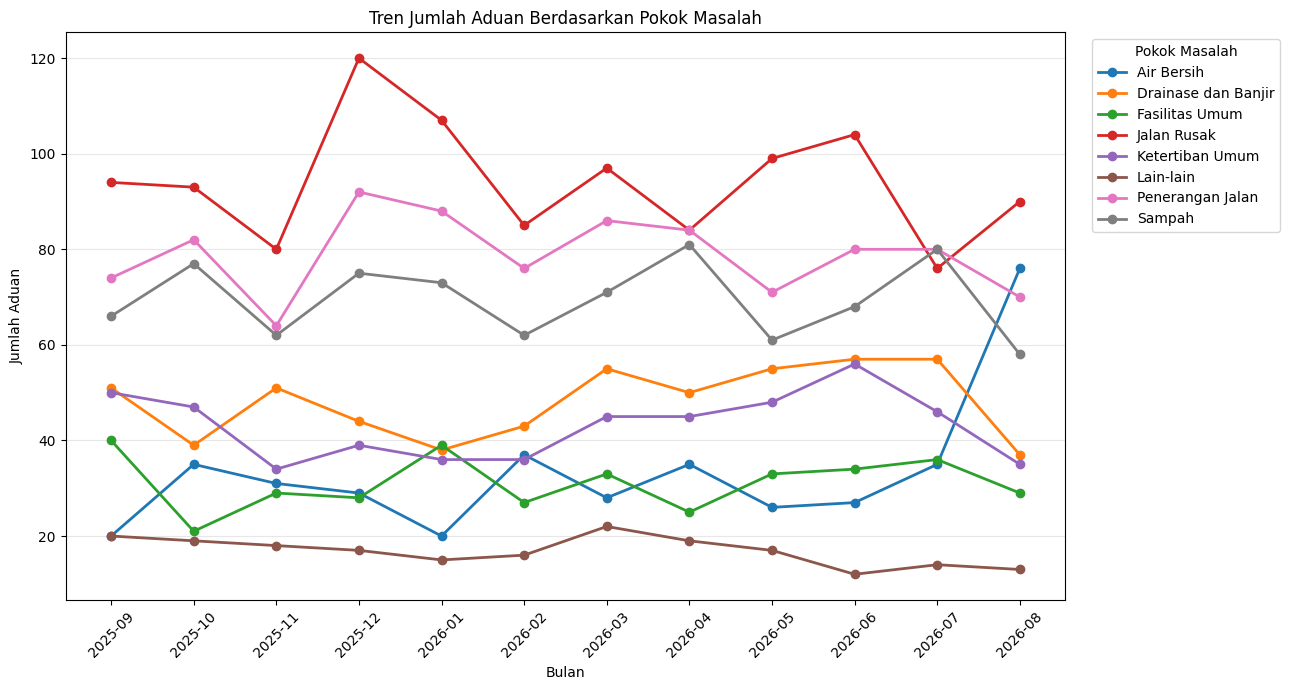


PERBANDINGAN RATA-RATA 3 BULAN AWAL DAN AKHIR


,Topik,Rata-rata 3 Bulan Awal,Rata-rata 3 Bulan Akhir,Perubahan Jumlah (%),Rata-rata Persentase Awal (%),Rata-rata Persentase Akhir (%),Perubahan Persentase (poin)
0,Air Bersih,28.67,46.00,60.47,7.14,10.86,3.72
2,Fasilitas Umum,30.00,33.00,10.00,7.44,7.69,0.25
1,Drainase dan Banjir,47.00,50.33,7.09,11.71,11.70,-0.01
4,Ketertiban Umum,43.67,45.67,4.58,10.75,10.61,-0.14
6,Penerangan Jalan,73.33,76.67,4.55,18.11,17.87,-0.24
3,Jalan Rusak,89.00,90.00,1.12,22.01,20.99,-1.02
7,Sampah,68.33,68.67,0.49,16.90,16.00,-0.91
5,Lain-lain,19.00,13.00,-31.58,4.71,3.04,-1.67



Hasil analisis tren berhasil disimpan.


In [94]:
# ============================================================
# B.2.2 - ANALISIS TREN BULANAN POKOK MASALAH
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Gabungkan tanggal dan hasil klasifikasi
df_tren = aduan_df[["id_aduan", "tanggal_parsed"]].merge(
    df_b1_final[["id_aduan", "pokok_masalah_final"]],
    on="id_aduan",
    how="inner",
    validate="one_to_one"
)

df_tren = df_tren.dropna(subset=["tanggal_parsed"]).copy()

# 2. Buat periode bulanan
df_tren["bulan"] = (
    df_tren["tanggal_parsed"].dt.to_period("M")
)

# Keluarkan aduan yang tidak dapat diklasifikasikan
df_tren_analisis = df_tren[
    df_tren["pokok_masalah_final"] != "Tidak dapat diklasifikasikan"
].copy()

# 3. Hitung jumlah aduan setiap topik per bulan
jumlah_bulanan = pd.crosstab(
    df_tren_analisis["bulan"],
    df_tren_analisis["pokok_masalah_final"]
)

# Pastikan urutan bulan lengkap
semua_bulan = pd.period_range(
    start=df_tren["bulan"].min(),
    end=df_tren["bulan"].max(),
    freq="M"
)

jumlah_bulanan = jumlah_bulanan.reindex(
    semua_bulan,
    fill_value=0
)

jumlah_bulanan.index = jumlah_bulanan.index.astype(str)

# 4. Hitung persentase setiap topik terhadap seluruh aduan per bulan
total_bulanan = (
    df_tren.groupby("bulan")
    .size()
    .reindex(semua_bulan, fill_value=0)
)

persentase_bulanan = jumlah_bulanan.div(
    total_bulanan.values,
    axis=0
) * 100

# 5. Tampilkan tabel jumlah aduan bulanan
print("JUMLAH ADUAN PER TOPIK SETIAP BULAN")
display(jumlah_bulanan)

# 6. Visualisasi tren jumlah aduan
plt.figure(figsize=(13, 7))

for topik in jumlah_bulanan.columns:
    plt.plot(
        jumlah_bulanan.index,
        jumlah_bulanan[topik],
        marker="o",
        linewidth=2,
        label=topik
    )

plt.title("Tren Jumlah Aduan Berdasarkan Pokok Masalah")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Aduan")
plt.xticks(rotation=45)
plt.legend(title="Pokok Masalah", bbox_to_anchor=(1.02, 1),
           loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

plt.savefig(
    os.path.join(OUTPUT_DIR, "tren_bulanan_pokok_masalah.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Bandingkan rata-rata 3 bulan pertama dan 3 bulan terakhir
awal = jumlah_bulanan.iloc[:3].mean()
akhir = jumlah_bulanan.iloc[-3:].mean()

awal_persen = persentase_bulanan.iloc[:3].mean()
akhir_persen = persentase_bulanan.iloc[-3:].mean()

rekap_tren = pd.DataFrame({
    "Topik": jumlah_bulanan.columns,
    "Rata-rata 3 Bulan Awal": awal.values,
    "Rata-rata 3 Bulan Akhir": akhir.values,
    "Perubahan Jumlah (%)": (
        (akhir.values - awal.values) /
        awal.values * 100
    ),
    "Rata-rata Persentase Awal (%)": awal_persen.values,
    "Rata-rata Persentase Akhir (%)": akhir_persen.values,
    "Perubahan Persentase (poin)": (
        akhir_persen.values - awal_persen.values
    )
})

rekap_tren["Perubahan Jumlah (%)"] = (
    rekap_tren["Perubahan Jumlah (%)"].round(2)
)

rekap_tren["Perubahan Persentase (poin)"] = (
    rekap_tren["Perubahan Persentase (poin)"].round(2)
)

rekap_tren = rekap_tren.sort_values(
    "Perubahan Jumlah (%)",
    ascending=False
)

print("\nPERBANDINGAN RATA-RATA 3 BULAN AWAL DAN AKHIR")
display(rekap_tren.round(2))

# 8. Simpan hasil analisis
jumlah_bulanan.to_csv(
    os.path.join(TABLE_DIR, "tren_jumlah_aduan_bulanan.csv")
)

persentase_bulanan.to_csv(
    os.path.join(TABLE_DIR, "tren_persentase_aduan_bulanan.csv")
)

rekap_tren.to_csv(
    os.path.join(TABLE_DIR, "perbandingan_tren_pokok_masalah.csv"),
    index=False
)

print("\nHasil analisis tren berhasil disimpan.")

## PEMERIKSAAN LONJAKAN ADUAN AIR BERSIH AGUSTUS 2026

In [95]:
# ============================================================
# PEMERIKSAAN LONJAKAN ADUAN AIR BERSIH AGUSTUS 2026
# ============================================================

df_air_agustus = df_tren[
    (df_tren["bulan"] == pd.Period("2026-08")) &
    (df_tren["pokok_masalah_final"] == "Air Bersih")
].merge(
    aduan_df[["id_aduan", "kategori_dilaporkan", "teks_aman"]],
    on="id_aduan",
    how="left"
)

print("Jumlah aduan Air Bersih Agustus 2026:",
      len(df_air_agustus))

print("\nDistribusi kategori yang dilaporkan:")
display(
    df_air_agustus["kategori_dilaporkan"]
    .value_counts()
    .rename_axis("Kategori Dilaporkan")
    .reset_index(name="Jumlah")
)

print("\nSeluruh teks aduan Air Bersih Agustus 2026:")
display(
    df_air_agustus[
        ["id_aduan", "kategori_dilaporkan", "teks_aman"]
    ].reset_index(drop=True)
)

Jumlah aduan Air Bersih Agustus 2026: 76

Distribusi kategori yang dilaporkan:


,Kategori Dilaporkan,Jumlah
0,Air Bersih,56
1,Ketertiban Umum,7
2,Fasilitas Umum,5
3,Penerangan Jalan,3
4,Lain-lain,3
5,Sampah,1
6,Jalan Rusak,1



Seluruh teks aduan Air Bersih Agustus 2026:


,id_aduan,kategori_dilaporkan,teks_aman
0,ADU-004102,Air Bersih,"mohon perhatiannya, air keruh kekuningan sudah 8 hari di komplek taman asih. mohon petugas datan..."
1,ADU-000143,Air Bersih,"yth. bapak/ibu wali kota, air pdam keruh berwarna coklat sejak 3 hari terakhir. mohon maaf bila ..."
2,ADU-002029,Penerangan Jalan,"mohon bantuan bapak/ibu, air keruh kekuningan sudah 3 hari di perumahan griya asri. mohon ditind..."
3,ADU-002934,Air Bersih,"mohon bantuan bapak/ibu, aliran air kecil sekali pada jam sibuk di gang kenanga. kami mohon sege..."
4,ADU-003840,Ketertiban Umum,"mohon bantuan bapak/ibu, air pdam di rumah saya keruh sehingga tidak bisa dipakai memasak. atas ..."
5,ADU-004213,Air Bersih,"selamat pagi bapak/ibu, air keruh kekuningan sudah 4 hari di jalan dahlia ujung. mohon maaf bila..."
6,ADU-002442,Air Bersih,"selamat pagi bapak/ibu, air pdam di rumah saya keruh sehingga tidak bisa dipakai memasak. demiki..."
7,ADU-001504,Air Bersih,"yth. bapak/ibu wali kota, air keruh kekuningan sudah 3 hari di gang mawar dalam. mohon petugas d..."
8,ADU-003251,Air Bersih,"mohon bantuan bapak/ibu, air bersih keruh dan mengendap lumpur di bak mandi. banyak anak sekolah..."
9,ADU-003240,Air Bersih,"selamat siang, saya warga di lokasi berikut, air keruh dan berbau kaporit keluar dari keran ruma..."


## PEMERIKSAAN POLA TEKS DAN SEBARAN WILAYAH

In [96]:
# ============================================================
# PEMERIKSAAN POLA TEKS DAN SEBARAN WILAYAH
# AIR BERSIH - AGUSTUS 2026
# ============================================================

# Ambil data Air Bersih Agustus 2026
df_air_agustus_lengkap = df_air_agustus.merge(
    aduan_df[["id_aduan", "kelurahan"]],
    on="id_aduan",
    how="left"
)

# 1. Pemeriksaan teks yang berulang
rekap_teks = (
    df_air_agustus_lengkap
    .groupby("teks_aman")
    .agg(
        Jumlah=("id_aduan", "count"),
        Jumlah_Wilayah=("kelurahan", "nunique")
    )
    .reset_index()
    .sort_values("Jumlah", ascending=False)
)

print("JUMLAH TEKS UNIK:",
      df_air_agustus_lengkap["teks_aman"].nunique())

print("JUMLAH TEKS BERULANG:",
      (rekap_teks["Jumlah"] > 1).sum())

print("\nTEKS YANG PALING SERING MUNCUL:")
display(rekap_teks.head(10))

# 2. Pemeriksaan sebaran wilayah
rekap_wilayah = (
    df_air_agustus_lengkap["kelurahan"]
    .value_counts()
    .rename_axis("Kelurahan")
    .reset_index(name="Jumlah Aduan")
)

print("\nDISTRIBUSI ADUAN BERDASARKAN KELURAHAN:")
display(rekap_wilayah)

JUMLAH TEKS UNIK: 76
JUMLAH TEKS BERULANG: 0

TEKS YANG PALING SERING MUNCUL:


,teks_aman,Jumlah,Jumlah_Wilayah
0,air bersih keruh dan mengendap lumpur di bak mandi. kondisi ini sudah dilaporkan ke rw tetapi be...,1,1
1,air bersih keruh dan mengendap lumpur di bak mandi. mohon maaf bila mengganggu waktu bapak/ibu. ...,1,1
2,air keruh kekuningan sudah 3 hari di komplek taman asih. sebelumnya terima kasih atas perhatian ...,1,1
3,air pdam di rumah saya keruh sehingga tidak bisa dipakai memasak. sebelumnya terima kasih atas p...,1,1
4,air pdam keruh berwarna coklat sejak 8 hari terakhir. mohon maaf bila mengganggu waktu bapak/ibu...,1,1
5,"assalamualaikum bapak/ibu, air bersih keruh dan mengendap lumpur di bak mandi. mohon kiranya dap...",1,1
6,"assalamualaikum bapak/ibu, air bersih keruh dan mengendap lumpur di bak mandi. mohon petugas dat...",1,1
7,"assalamualaikum bapak/ibu, air bersih keruh dan mengendap lumpur di bak mandi. mohon segera diti...",1,1
8,"assalamualaikum bapak/ibu, air keruh dan berbau kaporit keluar dari keran rumah kami. mohon kira...",1,1
9,"assalamualaikum bapak/ibu, air keruh dan berbau kaporit keluar dari keran rumah kami. mohon sege...",1,1



DISTRIBUSI ADUAN BERDASARKAN KELURAHAN:


,Kelurahan,Jumlah Aduan
0,Mekarjaya,13
1,Babakan Sari,12
2,Cikawao,9
3,Antapani Wetan,8
4,Cibuntu Kaler,7
5,Kebon Gedang,7
6,Cisaranten,6
7,Sekejati,4
8,Margahayu Kidul,4
9,Ciburial,3


# VISUALISASI DAN INTERPRETASI TEMUAN

Total data: 5049
Tanggal valid: 5049
Tanggal tidak valid: 0

Rentang waktu:
2025-09-01 00:00:00
2026-08-31 00:00:00

Persiapan data berhasil.
B.1 - DISTRIBUSI POKOK MASALAH ADUAN


,Pokok Masalah,Jumlah Aduan,Persentase (%)
0,Jalan Rusak,1129,22.36
1,Penerangan Jalan,947,18.76
2,Sampah,834,16.52
3,Drainase dan Banjir,577,11.43
4,Ketertiban Umum,517,10.24
5,Air Bersih,399,7.90
6,Fasilitas Umum,374,7.41
7,Lain-lain,202,4.00
8,Tidak dapat diklasifikasikan,70,1.39


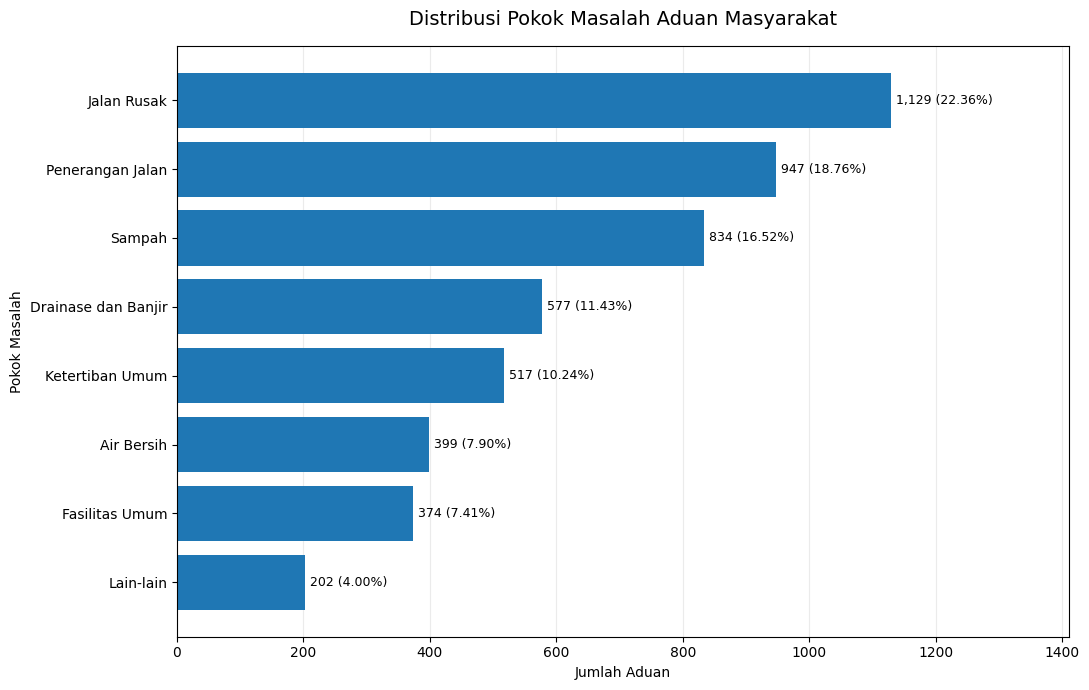


B.2 - TREN JUMLAH ADUAN PER TOPIK SETIAP BULAN


pokok_masalah_final,Air Bersih,Drainase dan Banjir,Fasilitas Umum,Jalan Rusak,Ketertiban Umum,Lain-lain,Penerangan Jalan,Sampah
2025-09,20,51,40,94,50,20,74,66
2025-10,35,39,21,93,47,19,82,77
2025-11,31,51,29,80,34,18,64,62
2025-12,29,44,28,120,39,17,92,75
2026-01,20,38,39,107,36,15,88,73
2026-02,37,43,27,85,36,16,76,62
2026-03,28,55,33,97,45,22,86,71
2026-04,35,50,25,84,45,19,84,81
2026-05,26,55,33,99,48,17,71,61
2026-06,27,57,34,104,56,12,80,68


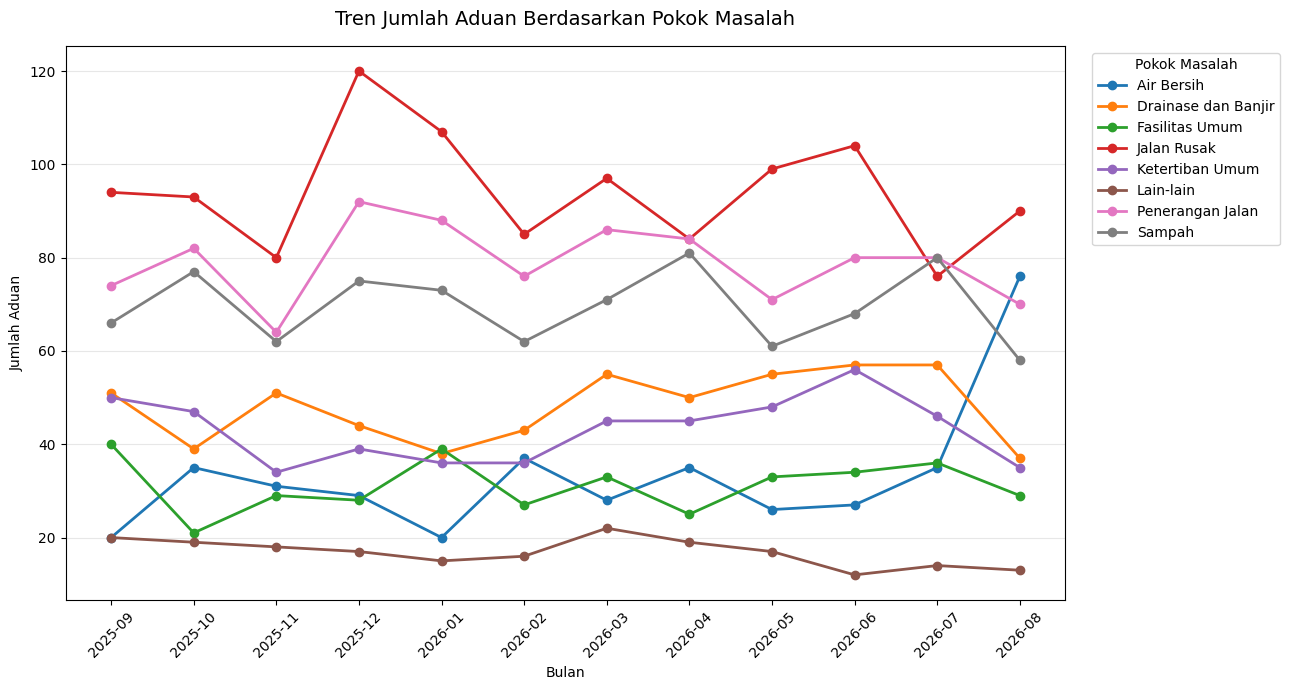

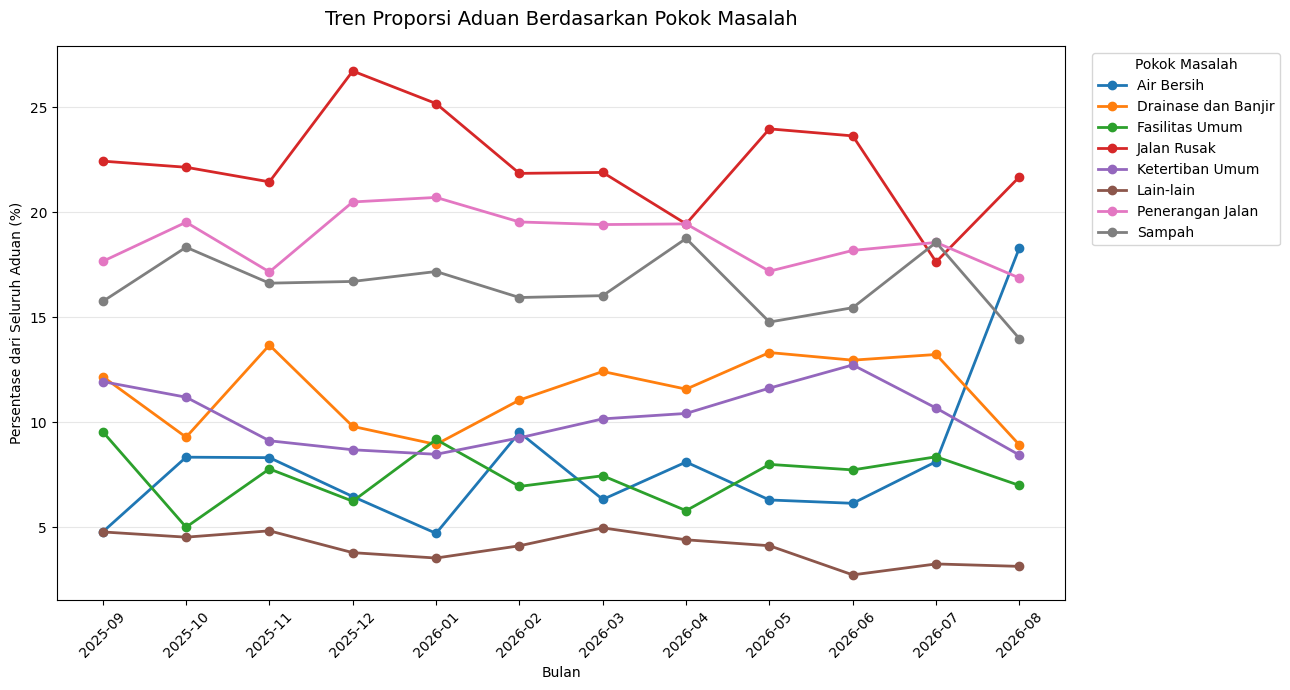


PERBANDINGAN RATA-RATA TIGA BULAN AWAL DAN AKHIR


,Topik,Rata-rata 3 Bulan Awal,Rata-rata 3 Bulan Akhir,Perubahan Jumlah (%),Pangsa Awal (%),Pangsa Akhir (%),Perubahan Pangsa (poin)
0,Air Bersih,28.67,46.00,60.47,7.14,10.86,3.72
2,Fasilitas Umum,30.00,33.00,10.00,7.44,7.69,0.25
1,Drainase dan Banjir,47.00,50.33,7.09,11.71,11.70,-0.01
4,Ketertiban Umum,43.67,45.67,4.58,10.75,10.61,-0.14
6,Penerangan Jalan,73.33,76.67,4.55,18.11,17.87,-0.24
3,Jalan Rusak,89.00,90.00,1.12,22.01,20.99,-1.02
7,Sampah,68.33,68.67,0.49,16.90,16.00,-0.91
5,Lain-lain,19.00,13.00,-31.58,4.71,3.04,-1.67



INTERPRETASI TEMUAN B.1
Topik dengan jumlah aduan terbanyak adalah Jalan Rusak, dengan 1,129 aduan (22.36%).
Tiga topik terbesar mencakup 2,910 aduan atau 57.64% dari seluruh korpus.
Aduan yang tidak dapat diklasifikasikan berjumlah 70 (1.39%).

INTERPRETASI TEMUAN B.2
Topik dengan peningkatan rata-rata terbesar antara tiga bulan awal dan akhir adalah Air Bersih.
Rata-rata tiga bulan awal: 28.67 aduan/bulan.
Rata-rata tiga bulan akhir: 46.00 aduan/bulan.
Perubahan jumlah: 60.47%.
Perubahan pangsa aduan: 3.72 poin persentase.

Topik dengan kenaikan jumlah terbesar pada bulan terakhir (2026-08) adalah Air Bersih, dengan perubahan +41 aduan dibandingkan bulan sebelumnya.

Catatan: peningkatan jumlah aduan merupakan indikasi meningkatnya laporan dalam korpus, bukan bukti langsung bahwa kondisi masalah di lapangan memburuk.

SELESAI - SEMUA VISUALISASI DAN TABEL TELAH DISIMPAN

Folder visualisasi: /content/Tugas3-Visualisasi-Data-Teks/outputs
Folder tabel: /content/Tugas3-Visualisasi-Data-

In [98]:

# ==============================================================
# TUGAS 3 VISUALISASI DATA TEKS
# BAGIAN B.1 DAN B.2
# VISUALISASI DAN INTERPRETASI TEMUAN
# ==============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


# --------------------------------------------------------------
# 1. PERSIAPAN DATA DAN DIREKTORI (PERBAIKAN)
# --------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Pastikan direktori tersedia
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

# Ambil data klasifikasi tanpa kolom tanggal lama
df_visual = df_b1_final.drop(
    columns=["tanggal_parsed", "tanggal"],
    errors="ignore"
).copy()

# Ambil tanggal dari dataset asli
df_tanggal_visual = aduan_df[
    ["id_aduan", "tanggal_parsed"]
].copy()

# Gabungkan berdasarkan ID aduan
df_visual = df_visual.merge(
    df_tanggal_visual,
    on="id_aduan",
    how="left",
    validate="one_to_one"
)

# Pastikan format tanggal benar
df_visual["tanggal_parsed"] = pd.to_datetime(
    df_visual["tanggal_parsed"],
    errors="coerce"
)

# Periksa hasil penggabungan
print("Total data:", len(df_visual))
print(
    "Tanggal valid:",
    df_visual["tanggal_parsed"].notna().sum()
)
print(
    "Tanggal tidak valid:",
    df_visual["tanggal_parsed"].isna().sum()
)

# Hapus data tanpa tanggal valid
df_visual = df_visual.dropna(
    subset=["tanggal_parsed"]
).copy()

# Buat periode bulanan
df_visual["bulan"] = (
    df_visual["tanggal_parsed"].dt.to_period("M")
)

print("\nRentang waktu:")
print(df_visual["tanggal_parsed"].min())
print(df_visual["tanggal_parsed"].max())

print("\nPersiapan data berhasil.")


# --------------------------------------------------------------
# 2. B.1 - DISTRIBUSI POKOK MASALAH
# --------------------------------------------------------------

rekap_distribusi = (
    df_visual["pokok_masalah_final"]
    .value_counts()
    .rename_axis("Pokok Masalah")
    .reset_index(name="Jumlah Aduan")
)

rekap_distribusi["Persentase (%)"] = (
    rekap_distribusi["Jumlah Aduan"] /
    len(df_visual) * 100
).round(2)

# Pisahkan topik yang berhasil diklasifikasikan
topik_valid = rekap_distribusi[
    rekap_distribusi["Pokok Masalah"] !=
    "Tidak dapat diklasifikasikan"
].copy()

topik_valid = topik_valid.sort_values(
    "Jumlah Aduan",
    ascending=True
)

print("=" * 70)
print("B.1 - DISTRIBUSI POKOK MASALAH ADUAN")
print("=" * 70)

display(rekap_distribusi)

# Visualisasi 1: Diagram batang horizontal
fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    topik_valid["Pokok Masalah"],
    topik_valid["Jumlah Aduan"]
)

for bar, (_, row) in zip(
    bars, topik_valid.iterrows()
):
    ax.text(
        bar.get_width() + 8,
        bar.get_y() + bar.get_height() / 2,
        f'{row["Jumlah Aduan"]:,} '
        f'({row["Persentase (%)"]:.2f}%)',
        va="center",
        fontsize=9
    )

ax.set_title(
    "Distribusi Pokok Masalah Aduan Masyarakat",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Jumlah Aduan")
ax.set_ylabel("Pokok Masalah")
ax.set_xlim(0, topik_valid["Jumlah Aduan"].max() * 1.25)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "01_distribusi_pokok_masalah.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------------------
# 3. B.2 - TREN JUMLAH ADUAN PER BULAN
# --------------------------------------------------------------

# Keluarkan aduan yang tidak dapat diklasifikasikan
df_tren_visual = df_visual[
    df_visual["pokok_masalah_final"] !=
    "Tidak dapat diklasifikasikan"
].copy()

# Rentang bulan lengkap
semua_bulan = pd.period_range(
    start=df_visual["bulan"].min(),
    end=df_visual["bulan"].max(),
    freq="M"
)

# Jumlah aduan per topik setiap bulan
tren_jumlah = pd.crosstab(
    df_tren_visual["bulan"],
    df_tren_visual["pokok_masalah_final"]
).reindex(
    semua_bulan,
    fill_value=0
)

tren_jumlah.index = tren_jumlah.index.astype(str)

# Total aduan setiap bulan, termasuk yang tidak terklasifikasi
total_bulanan = (
    df_visual.groupby("bulan")
    .size()
    .reindex(semua_bulan, fill_value=0)
)

total_bulanan.index = total_bulanan.index.astype(str)

# Persentase setiap topik terhadap seluruh aduan bulanan
tren_persentase = tren_jumlah.div(
    total_bulanan,
    axis=0
) * 100

print("\n" + "=" * 70)
print("B.2 - TREN JUMLAH ADUAN PER TOPIK SETIAP BULAN")
print("=" * 70)

display(tren_jumlah)

# --------------------------------------------------------------
# 4. VISUALISASI 2 - GRAFIK TREN JUMLAH ADUAN
# --------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

for topik in tren_jumlah.columns:
    ax.plot(
        tren_jumlah.index,
        tren_jumlah[topik],
        marker="o",
        linewidth=2,
        label=topik
    )

ax.set_title(
    "Tren Jumlah Aduan Berdasarkan Pokok Masalah",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah Aduan")
ax.tick_params(axis="x", rotation=45)
ax.legend(
    title="Pokok Masalah",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "02_tren_jumlah_aduan_bulanan.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------------------
# 5. VISUALISASI 3 - TREN PERSENTASE ADUAN
# --------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

for topik in tren_persentase.columns:
    ax.plot(
        tren_persentase.index,
        tren_persentase[topik],
        marker="o",
        linewidth=2,
        label=topik
    )

ax.set_title(
    "Tren Proporsi Aduan Berdasarkan Pokok Masalah",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Bulan")
ax.set_ylabel("Persentase dari Seluruh Aduan (%)")
ax.tick_params(axis="x", rotation=45)
ax.legend(
    title="Pokok Masalah",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "03_tren_persentase_aduan_bulanan.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------------------
# 6. PERBANDINGAN TIGA BULAN AWAL DAN AKHIR
# --------------------------------------------------------------

# Rata-rata tiga bulan awal
rata_awal = tren_jumlah.iloc[:3].mean()
persen_awal = tren_persentase.iloc[:3].mean()

# Rata-rata tiga bulan akhir
rata_akhir = tren_jumlah.iloc[-3:].mean()
persen_akhir = tren_persentase.iloc[-3:].mean()

rekap_tren = pd.DataFrame({
    "Topik": tren_jumlah.columns,
    "Rata-rata 3 Bulan Awal": rata_awal.values,
    "Rata-rata 3 Bulan Akhir": rata_akhir.values,
    "Perubahan Jumlah (%)": np.where(
        rata_awal.values != 0,
        (rata_akhir.values - rata_awal.values) /
        rata_awal.values * 100,
        np.nan
    ),
    "Pangsa Awal (%)": persen_awal.values,
    "Pangsa Akhir (%)": persen_akhir.values,
    "Perubahan Pangsa (poin)": (
        persen_akhir.values - persen_awal.values
    )
})

rekap_tren = rekap_tren.sort_values(
    "Perubahan Jumlah (%)",
    ascending=False
)

print("\n" + "=" * 70)
print("PERBANDINGAN RATA-RATA TIGA BULAN AWAL DAN AKHIR")
print("=" * 70)

display(rekap_tren.round(2))

# --------------------------------------------------------------
# 7. IDENTIFIKASI TEMUAN UTAMA SECARA OTOMATIS
# --------------------------------------------------------------

topik_tertinggi = topik_valid.sort_values(
    "Jumlah Aduan",
    ascending=False
).iloc[0]

topik_kenaikan = rekap_tren.iloc[0]

print("\n" + "=" * 70)
print("INTERPRETASI TEMUAN B.1")
print("=" * 70)

print(
    f"Topik dengan jumlah aduan terbanyak adalah "
    f"{topik_tertinggi['Pokok Masalah']}, "
    f"dengan {int(topik_tertinggi['Jumlah Aduan']):,} aduan "
    f"({topik_tertinggi['Persentase (%)']:.2f}%)."
)

tiga_teratas = topik_valid.nlargest(
    3, "Jumlah Aduan"
)

jumlah_tiga = tiga_teratas["Jumlah Aduan"].sum()
persen_tiga = jumlah_tiga / len(df_visual) * 100

print(
    f"Tiga topik terbesar mencakup {jumlah_tiga:,} aduan "
    f"atau {persen_tiga:.2f}% dari seluruh korpus."
)

tidak_terklasifikasi = (
    df_visual["pokok_masalah_final"] ==
    "Tidak dapat diklasifikasikan"
).sum()

print(
    f"Aduan yang tidak dapat diklasifikasikan berjumlah "
    f"{tidak_terklasifikasi} "
    f"({tidak_terklasifikasi / len(df_visual) * 100:.2f}%)."
)

# --------------------------------------------------------------
# 8. INTERPRETASI TEMUAN B.2
# --------------------------------------------------------------

print("\n" + "=" * 70)
print("INTERPRETASI TEMUAN B.2")
print("=" * 70)

print(
    f"Topik dengan peningkatan rata-rata terbesar antara "
    f"tiga bulan awal dan akhir adalah "
    f"{topik_kenaikan['Topik']}."
)

print(
    f"Rata-rata tiga bulan awal: "
    f"{topik_kenaikan['Rata-rata 3 Bulan Awal']:.2f} aduan/bulan."
)

print(
    f"Rata-rata tiga bulan akhir: "
    f"{topik_kenaikan['Rata-rata 3 Bulan Akhir']:.2f} aduan/bulan."
)

print(
    f"Perubahan jumlah: "
    f"{topik_kenaikan['Perubahan Jumlah (%)']:.2f}%."
)

print(
    f"Perubahan pangsa aduan: "
    f"{topik_kenaikan['Perubahan Pangsa (poin)']:.2f} "
    f"poin persentase."
)

# Perubahan bulan terakhir dibandingkan bulan sebelumnya
perubahan_terakhir = (
    tren_jumlah.iloc[-1] - tren_jumlah.iloc[-2]
)

persen_perubahan_terakhir = (
    perubahan_terakhir /
    tren_jumlah.iloc[-2].replace(0, np.nan) * 100
)

topik_lonjakan = perubahan_terakhir.idxmax()

print(
    f"\nTopik dengan kenaikan jumlah terbesar pada bulan "
    f"terakhir ({tren_jumlah.index[-1]}) adalah "
    f"{topik_lonjakan}, dengan perubahan "
    f"{int(perubahan_terakhir[topik_lonjakan]):+d} aduan "
    f"dibandingkan bulan sebelumnya."
)

print(
    "\nCatatan: peningkatan jumlah aduan merupakan indikasi "
    "meningkatnya laporan dalam korpus, bukan bukti langsung "
    "bahwa kondisi masalah di lapangan memburuk."
)

# --------------------------------------------------------------
# 9. SIMPAN SEMUA TABEL HASIL
# --------------------------------------------------------------

rekap_distribusi.to_csv(
    os.path.join(
        TABLE_DIR,
        "final_distribusi_pokok_masalah.csv"
    ),
    index=False
)

tren_jumlah.to_csv(
    os.path.join(
        TABLE_DIR,
        "final_tren_jumlah_bulanan.csv"
    )
)

tren_persentase.to_csv(
    os.path.join(
        TABLE_DIR,
        "final_tren_persentase_bulanan.csv"
    )
)

rekap_tren.to_csv(
    os.path.join(
        TABLE_DIR,
        "final_perbandingan_tren.csv"
    ),
    index=False
)

# --------------------------------------------------------------
# 10. DAFTAR OUTPUT
# --------------------------------------------------------------

print("\n" + "=" * 70)
print("SELESAI - SEMUA VISUALISASI DAN TABEL TELAH DISIMPAN")
print("=" * 70)

print("\nFolder visualisasi:", OUTPUT_DIR)
print("Folder tabel:", TABLE_DIR)

print("\nFile visualisasi:")
print("- 01_distribusi_pokok_masalah.png")
print("- 02_tren_jumlah_aduan_bulanan.png")
print("- 03_tren_persentase_aduan_bulanan.png")

print("\nFile tabel:")
print("- final_distribusi_pokok_masalah.csv")
print("- final_tren_jumlah_bulanan.csv")
print("- final_tren_persentase_bulanan.csv")
print("- final_perbandingan_tren.csv")
